# When Catalogs Become Preferences — experiment notebook

A from-scratch re-implementation of the controlled study, written on 2026-11-15.
It follows the design described in the paper draft and adds the experiments the
review asked for. **Numbers here replace the ones in draft v5; they are not expected
to match them**, because the original seeds and construction details were not available.

| Section | What it does | Needs model calls |
|---|---|---|
| 1–3 | Catalog, paired sub-catalogs, users, interaction engine | no |
| 4 | Step 0: equivalence check, logical reference, naive rule | no |
| 5 | Writers: five prompt arms, cached model calls | **yes** |
| 6 | Experiment 1: unbundling the writing interface | **yes** (reference rows: no) |
| 7 | Experiment 2: scoring against three user types | **yes** (reference rows: no) |
| 8 | Experiment 3: closed loop, written memory served on both catalogs | partly |
| 9 | Experiment 4: entrenchment curves | partly |
| 10 | Experiment 5: update rules under noise | no |
| 11 | Figure and summary | no |

**Choices the draft leaves open, made here** (each is one line in `CFG` or one function):
a history is one bootstrap acceptance plus k visits; the proposal order is frozen per user,
not per catalog; the four periods are before 1950, 1950-1979, 1980-1999 and 2000 onward; the few
works from the paired country in another language are all kept in the background, so that a
country-only requirement can be told apart from a language-and-country one; relaxation also
applies when every book that passes the filters has been rejected.

**Known limitation, found after this run (2026-11-15).** The engine lets a book that was
already proposed to a user be proposed to that user again when a request repeats, and the
constructed catalogs are thin (a request typically matches one or two target-language books).
A check without repeated proposals changes two findings of sections 8-9: soft ranking no
longer leaves the country question unresolved (37.2% resolved at visit 16, against 46.9%
without memory and 12.8% under the hard filter), and adding the country rule to the language
rule costs 2.5 points of success on the learning catalog instead of 0. The horizons of 64 and
256 visits in section 10 exceed what these catalogs can supply without repeats. Treat those
numbers as provisional until the engine is changed.

**To enable the model calls** put `BASETEN_API_KEY=...` in a file named `.env` next to
this notebook (or export it) and re-run. Responses are cached in `cache/`, so a re-run
only pays for calls it has not made before. Without a key every model-dependent cell
reports "not run" and the rest of the notebook still executes.

In [1]:
import collections, hashlib, itertools, json, math, os, random, re, statistics, sys, threading, time
import urllib.error, urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)

ROOT = Path.cwd()
DATA, RESULTS, FIGS, CACHE = ROOT / "data", ROOT / "results", ROOT / "figures", ROOT / "cache"
for d in (DATA, RESULTS, FIGS, CACHE):
    d.mkdir(exist_ok=True)

CFG = {
    "seed": 20261115,
    # (target language, paired country, number of target-language works per catalog)
    "pairs": [("Spanish", "Spain", 90), ("French", "France", 80), ("Russian", "Russia", 50), ("German", "Germany", 40)],
    "catalog_size": 1200,
    "skew_learn": 0.90,      # share of target-language works from the paired country, learning catalog C0
    "skew_shift": 0.10,      # same share after the shift, catalog C1
    "periods": [("before 1950", None, 1949), ("1950-1979", 1950, 1979), ("1980-1999", 1980, 1999), ("2000 onward", 2000, None)],
    "B": 5,                  # proposals per visit
    "history_visits": 16, "prefixes": [4, 8, 16], "main_prefix": 8,
    "n_write_users": 20,     # per pair: histories sent to the model writers
    "n_serve_users": 80,     # per pair: users in the serving audit (the first 20 are the writing users)
    "cont_visits": 16,       # continuation visits in the serving audit
    "n_update_users": 500,   # per pair: users per cell of the update stress test
    "show_titles": True,
    "models": {"GPT-OSS-120B": "openai/gpt-oss-120b", "GLM-5.3-Flash": "zai-org/GLM-5.3-Flash"},
    "api_base": "https://inference.baseten.co/v1",
    "temperature": 0.1, "max_tokens": 6000, "n_samples": 1, "llm_workers": 8, "max_new_calls": 8000,
}
PERIOD_LABELS = [p[0] for p in CFG["periods"]]
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

python 3.12.13 | numpy 2.5.4 | pandas 3.1.1 | matplotlib 3.11.2


## 1. Catalog
The source is the τ-Rec-Books catalog (`books-wikidata-v2`, CC0), pinned to one commit and
checked against the SHA-256 that the benchmark's own manifest records.

In [2]:
CATALOG_URL = ("https://raw.githubusercontent.com/nbharaths/tau-rec/e96771e0d4ee7ddaff94f74e5080d4c3a184a4b8/"
               "data/tracks/books-wikidata-v2/catalog.json")
CATALOG_SHA256 = "19e9fa3a4db03de8f8bb8cdd8f7b231346a44f21cefca18947b7b10485d7093f"

def load_catalog():
    path = DATA / "catalog.json"
    if not path.exists():
        print("downloading catalog ...")
        urllib.request.urlretrieve(CATALOG_URL, path)
    raw = path.read_bytes()
    digest = hashlib.sha256(raw).hexdigest()
    assert digest == CATALOG_SHA256, f"catalog hash mismatch: {digest}"
    return json.loads(raw)

CATALOG = load_catalog()
POOL = [w for w in CATALOG if w["languages"] and w["countries"]]
print(f"catalog: {len(CATALOG):,} works | with language and country recorded: {len(POOL):,} | sha256 ok")

def period_of(year):
    for k, (_, lo, hi) in enumerate(CFG["periods"]):
        if (lo is None or year >= lo) and (hi is None or year <= hi):
            return k
    raise ValueError(year)

catalog: 20,000 works | with language and country recorded: 14,230 | sha256 ok


## 2. Paired sub-catalogs
For each language/country pair we build a learning catalog **C0** and a shifted catalog **C1**
of 1,200 works each. Both hold the same number of target-language works and the same
background; only the share of target-language works from the paired country changes
(90% in C0, 10% in C1). The two catalogs are nested as far as possible, so the shift swaps
works instead of redrawing them.

All randomness is derived from SHA-256 of the seed and a label, so the construction does
not depend on a library's random stream.

In [3]:
def hseed(*parts):
    s = "|".join(str(p) for p in (CFG["seed"],) + parts)
    return int.from_bytes(hashlib.sha256(s.encode()).digest()[:8], "big")

def hsorted(works, *parts):
    """Deterministic shuffle: order works by a seeded hash of their id."""
    tag = "|".join(str(p) for p in (CFG["seed"],) + parts)
    return sorted(works, key=lambda w: hashlib.sha256(f"{tag}|{w['id']}".encode()).digest())

class World:
    """One language/country pair: the union of C0 and C1, with flags and lookup tables."""

    def __init__(self, pidx, lang, country, n_t):
        self.pidx, self.lang, self.country, self.n_t = pidx, lang, country, n_t
        self.L, self.C = ("language", lang), ("country", country)
        target = [w for w in POOL if lang in w["languages"]]
        joint = hsorted([w for w in target if country in w["countries"]], "joint", pidx)
        other = hsorted([w for w in target if country not in w["countries"]], "other", pidx)
        self.natural = (len(joint), len(target))
        nj0 = round(CFG["skew_learn"] * n_t); no0 = n_t - nj0
        nj1 = round(CFG["skew_shift"] * n_t); no1 = n_t - nj1
        assert len(joint) >= nj0 and len(other) >= no1, (lang, len(joint), nj0, len(other), no1)
        J0, O1 = joint[:nj0], other[:no1]          # C0's joint works, C1's other-country works
        J1, O0 = J0[:nj1], O1[:no0]                # nested: C1's joint ⊂ C0's, C0's other ⊂ C1's
        self.spare_other = len(other) - no1
        bg_pool = [w for w in POOL if lang not in w["languages"]]
        forced = [w for w in bg_pool if country in w["countries"]]   # paired country, other language
        rest = hsorted([w for w in bg_pool if country not in w["countries"]], "bg", pidx)
        bg = forced + rest[: CFG["catalog_size"] - n_t - len(forced)]
        self.n_country_other_lang = len(forced)
        self.items = J0 + O1 + bg
        ids = [{w["id"] for w in J0 + O0 + bg}, {w["id"] for w in J1 + O1 + bg}]
        assert len(ids[0]) == len(ids[1]) == CFG["catalog_size"]
        n = len(self.items)
        self.in_cat = [[w["id"] in ids[c] for w in self.items] for c in (0, 1)]
        self.isL = [lang in w["languages"] for w in self.items]
        self.isC = [country in w["countries"] for w in self.items]
        self.period = [period_of(w["publication_year"]) for w in self.items]
        self.genres = [tuple(w["genres"]) for w in self.items]
        self._sat, self._ord, self._feas = {}, {}, {}
        # request cells: (genre, period index) -> item indices, per catalog
        self.cand = []
        for c in (0, 1):
            d = collections.defaultdict(list)
            for i in range(n):
                if self.in_cat[c][i]:
                    for g in self.genres[i]:
                        d[(g, self.period[i])].append(i)
            self.cand.append(dict(d))
        allc = sorted(set(self.cand[0]) | set(self.cand[1]))
        self.union = {c: sorted(set(self.cand[0].get(c, [])) | set(self.cand[1].get(c, []))) for c in allc}
        # feasible for a language-only user: a joint work in C0 and a target-language work in C1
        self.cells = [c for c in allc
                      if any(self.isL[i] and self.isC[i] for i in self.cand[0].get(c, []))
                      and any(self.isL[i] for i in self.cand[1].get(c, []))]
        self.joint0 = [i for i in range(n) if self.in_cat[0][i] and self.isL[i] and self.isC[i]]

    def sat(self, key):
        """Boolean list over items: does the item satisfy rule (field, value)?"""
        a = self._sat.get(key)
        if a is None:
            f, v = key
            if f == "language":
                a = [v in w["languages"] for w in self.items]
            elif f == "country":
                a = [v in w["countries"] for w in self.items]
            elif f == "genre":
                a = [v in w["genres"] for w in self.items]
            elif f == "period":
                a = [PERIOD_LABELS[p] == v for p in self.period]
            else:
                a = [False] * len(self.items)
            self._sat[key] = a
        return a

    def order(self, uidx, cell, cat):
        """Request-matching items of one catalog in this user's frozen proposal order.
        The order is drawn once per (user, cell) over the union of both catalogs, so a work
        keeps its relative position when the catalog shifts."""
        o = self._ord.get((uidx, cell))
        if o is None:
            u = self.union.get(cell, [])
            r = random.Random(hseed("order", self.pidx, uidx, cell[0], cell[1]))
            ranked = [i for _, i in sorted((r.random(), i) for i in u)]
            o = ([i for i in ranked if self.in_cat[0][i]], [i for i in ranked if self.in_cat[1][i]])
            self._ord[(uidx, cell)] = o
        return o[cat]

    def requests(self, uidx, n, stream="hist", cells=None):
        cells = self.cells if cells is None else cells
        r = random.Random(hseed("req", stream, self.pidx, uidx))
        return [cells[r.randrange(len(cells))] for _ in range(n)]

    def bootstrap(self, uidx):
        """One accepted joint work that every history starts from."""
        r = random.Random(hseed("boot", self.pidx, uidx))
        i = self.joint0[r.randrange(len(self.joint0))]
        g = self.genres[i][r.randrange(len(self.genres[i]))]
        return {"cell": (g, self.period[i]), "props": [(i, True)]}

    def truth(self, utype):
        """Standing requirements of a user type: language only, both, or country only."""
        return {"L": (self.L,), "LC": (self.L, self.C), "C": (self.C,)}[utype]

    def feasible(self, cell, cat, truth):
        """Does the catalog hold a book that meets the request and the user's requirements?"""
        key = (cell, cat, truth)
        f = self._feas.get(key)
        if f is None:
            ta = [self.sat(k) for k in truth]
            f = self._feas[key] = any(all(a[i] for a in ta) for i in self.cand[cat].get(cell, []))
        return f

WORLDS = [World(i, *p) for i, p in enumerate(CFG["pairs"])]

rows = []
for W in WORLDS:
    def share(c):
        t = [i for i in range(len(W.items)) if W.in_cat[c][i] and W.isL[i]]
        return sum(W.isC[i] for i in t) / len(t)
    other_c1 = [W.items[i] for i in range(len(W.items)) if W.in_cat[1][i] and W.isL[i] and not W.isC[i]]
    top_other = collections.Counter(c for w in other_c1 for c in w["countries"]).most_common(2)
    rows.append({
        "pair": f"{W.lang}/{W.country}", "target works": W.n_t,
        "from paired country, C0": f"{share(0):.0%}", "C1": f"{share(1):.0%}",
        "natural share in pool": f"{W.natural[0]}/{W.natural[1]} = {W.natural[0] / W.natural[1]:.1%}",
        "unused other-country works": W.spare_other,
        "paired country, other language": W.n_country_other_lang,
        "feasible request cells": len(W.cells),
        "C1 other-country works come from": ", ".join(f"{c} {n}" for c, n in top_other),
    })
CATALOG_TABLE = pd.DataFrame(rows)
print("total feasible request cells:", sum(len(W.cells) for W in WORLDS))
CATALOG_TABLE

total feasible request cells: 70


,pair,target works,"from paired country, C0",C1,natural share in pool,unused other-country works,"paired country, other language",feasible request cells,C1 other-country works come from
0,Spanish/Spain,90,90%,10%,86/229 = 37.6%,62,11,22,"Mexico 33, Argentina 14"
1,French/France,80,90%,10%,420/497 = 84.5%,5,4,23,"Belgium 37, Canada 12"
2,Russian/Russia,50,90%,10%,83/130 = 63.8%,2,4,8,"Soviet Union 38, Belarus 2"
3,German/Germany,40,90%,10%,190/227 = 83.7%,1,9,17,"Austria 14, Switzerland 13"


## 3. Interaction engine
One function runs a visit for every condition in the notebook. A memory is a set of rules
`(field, value)` with a status; a policy says how statuses are used.

* **hard / established / confirmed** rules filter under `enforce`; **plausible** rules only order books.
* `soft` treats every stored rule as an ordering signal and excludes nothing.
* `relax`: when nothing passes the filters, or everything that passes has been rejected and the
  visit still has budget, drop one blocking rule for the rest of this visit. If several single
  rules would unblock it, a seeded coin flip picks which to drop first and the others are tried in
  turn. Confirmed rules are never dropped. The stored memory is not changed.
* `update`: `("count", k)` deletes a rule after k accepted books that violate it;
  `("net", m)` adds a point when a book violating only that rule is rejected, removes one when a
  violating book is accepted, caps the score at +m and deletes at −m;
  `("demote", k)` turns a rule into a plausible one at the first violating acceptance and deletes it at k.
* `ask="neutral"`: one yes/no question per visit about one stored, unconfirmed rule.
  `ask="oracle"`: one question that reveals the full standing requirement (an upper bound).
* `probe`: once per rule, propose first a book that breaks only that rule.

In [4]:
FIRM = ("hard", "established", "confirmed")

class Memory:
    __slots__ = ("status", "acc", "net", "probed", "asked", "oracle_done")

    def __init__(self, rules=None):
        self.status = dict(rules or {})
        self.acc, self.net = collections.Counter(), collections.Counter()
        self.probed, self.asked, self.oracle_done = set(), set(), False

class Policy:
    def __init__(self, name, mode="enforce", relax=False, update=None, ask=None, probe=False):
        self.name, self.mode, self.relax, self.update, self.ask, self.probe = name, mode, relax, update, ask, probe

MEMORYLESS = Policy("memoryless", mode="none")

def relax_tail(order, filt, rank, st, sat, tie):
    """Books to fall back on once the filtered list is exhausted: for each filter rule that is not
    confirmed, the books that break that rule and no other filter. Rules are tried in a seeded
    random order."""
    opts = []
    for k in filt:
        if st.get(k) == "confirmed":
            continue
        ak, others = sat(k), [sat(j) for j in filt if j != k]
        e = [i for i in order if not ak[i] and all(a[i] for a in others)]
        if e:
            opts.append(e)
    if len(opts) > 1:
        tie.shuffle(opts)
    ra = [sat(k) for k in rank]
    out = []
    for e in opts:
        out += sorted(e, key=lambda i: -sum(a[i] for a in ra)) if ra else e
    return out

def run_visit(W, order, mem, pol, truth, B, tie, flip=None):
    """Run one visit. `order` is the request-matching part of the active catalog in the user's
    frozen order. `truth` is the tuple of rules the user really requires. `flip` is None or
    (rng, p_false_accept, p_false_reject). Returns (success, [(item, verdict)], questions, relaxed)."""
    st = mem.status
    sat = W.sat
    q = 0
    if pol.ask == "oracle":
        if not mem.oracle_done:
            mem.oracle_done, q = True, 1
            mem.status = st = {k: "confirmed" for k in truth}
    elif pol.ask == "neutral":
        pend = [k for k, s in st.items() if s != "confirmed" and k not in mem.asked]
        if pend:
            k = pend[tie.randrange(len(pend))]
            mem.asked.add(k); q = 1
            if k in truth:
                st[k] = "confirmed"
            else:
                del st[k]
    if pol.mode == "enforce":
        filt = [k for k, s in st.items() if s in FIRM]
        rank = [k for k, s in st.items() if s == "plausible"]
    elif pol.mode == "soft":
        filt, rank = [], list(st)
    else:
        filt, rank = [], []
    if filt:
        fa = [sat(k) for k in filt]
        elig = [i for i in order if all(a[i] for a in fa)]
    else:
        elig = list(order)
    if rank and len(elig) > 1:
        ra = [sat(k) for k in rank]
        elig = sorted(elig, key=lambda i: -sum(a[i] for a in ra))      # stable: frozen order within ties
    if pol.probe:
        todo = [k for k, s in st.items() if s != "confirmed" and k not in mem.probed]
        if todo:
            tie.shuffle(todo)
            for k in todo:
                ak = sat(k); oth = [sat(j) for j in st if j != k]
                c = [i for i in order if not ak[i] and all(a[i] for a in oth)]
                if c:
                    mem.probed.add(k)
                    elig = [c[0]] + [i for i in elig if i != c[0]]
                    break
    ta = [sat(k) for k in truth]
    upd = pol.update
    rec, success = [], False
    props, relaxed, j = elig[:B], False, 0
    while True:
        if j == len(props):
            # everything that passes the filters has been proposed (or nothing passes them)
            if relaxed or not (pol.relax and filt) or j >= B:
                break
            relaxed = True
            props = props + relax_tail(order, filt, rank, st, sat, tie)[: B - j]
            if j == len(props):
                break
        i = props[j]; j += 1
        ok = all(a[i] for a in ta)
        if flip is not None:
            x = flip[0].random()
            if ok:
                if x < flip[2]:
                    ok = False
            elif x < flip[1]:
                ok = True
        rec.append((i, ok))
        if upd is not None and st:
            viol = [k for k in st if not sat(k)[i]]
            if viol:
                kind, thr = upd
                if ok:
                    for k in viol:
                        mem.acc[k] += 1
                        mem.net[k] -= 1
                        if kind == "count":
                            if mem.acc[k] >= thr:
                                del st[k]
                        elif kind == "demote":
                            if mem.acc[k] >= thr:
                                del st[k]
                            elif st[k] in ("hard", "established"):
                                st[k] = "plausible"
                        elif kind == "net":
                            if mem.net[k] <= -thr:
                                del st[k]
                elif kind == "net" and len(viol) == 1:
                    k = viol[0]
                    mem.net[k] = min(thr, mem.net[k] + 1)
        if ok:
            success = True
            break
    return success, rec, q, relaxed

# ---- memoryless histories -------------------------------------------------------------
def gen_history(W, uidx, utype, n_visits=None):
    """Bootstrap acceptance, then `n_visits` visits on C0 with no memory."""
    n_visits = n_visits or CFG["history_visits"]
    truth = W.truth(utype)
    hist = [W.bootstrap(uidx)]
    mem, tie = Memory(), random.Random(0)
    for cell in W.requests(uidx, n_visits):
        _, rec, _, _ = run_visit(W, W.order(uidx, cell, 0), mem, MEMORYLESS, truth, CFG["B"], tie)
        hist.append({"cell": cell, "props": rec})
    return hist

def prefix(hist, k):
    """The bootstrap acceptance plus the first k visits."""
    return hist[: k + 1]

def has_counterexample(W, hist, rule):
    """An accepted book that violates `rule`: direct proof the rule is not required."""
    a = W.sat(rule)
    return any(ok and not a[i] for v in hist for i, ok in v["props"])

UTYPES = ("L", "LC", "C")
USERS = [(W, u) for W in WORLDS for u in range(CFG["n_serve_users"])]                   # 320
WRITE_USERS = [(W, u) for W in WORLDS for u in range(CFG["n_write_users"])]             # 80
HIST = {(W.pidx, u, t): gen_history(W, u, t) for W, u in USERS for t in UTYPES}
print(f"users: {len(USERS)} in the serving audit, of which {len(WRITE_USERS)} are sent to the model writers")

users: 320 in the serving audit, of which 80 are sent to the model writers


## 4. Step 0 — checks that need no model
* **Equivalence.** A history is *ambiguous* for the country rule when it contains no accepted
  target-language book from another country. For every such history we check that a user who
  requires language *and* country would have produced exactly the same history.
* **Logical reference.** For each history we compute, by rule, which predicates belong to every
  consistent set of requirements (*established*), to some (*plausible*), or to none.
* **Naive rule.** Store every attribute value shared by all accepted books.

In [5]:
def wilson(k, n, z=1.959964):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def pct(k, n, ci=True):
    if n == 0:
        return "n/a"
    s = f"{k}/{n} ({100 * k / n:.1f}%)"
    if ci:
        lo, hi = wilson(k, n)
        s += f" [{100 * lo:.1f}, {100 * hi:.1f}]"
    return s

def boot_ci(values, n_boot=5000, tag="boot"):
    """User-level percentile bootstrap for a mean. `values` holds one number per user."""
    v = np.asarray(values, dtype=float)
    rng = np.random.default_rng(hseed("bootstrap", tag) % (2**32))
    idx = rng.integers(0, len(v), size=(n_boot, len(v)))
    m = v[idx].mean(axis=1)
    return float(v.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def mcnemar_exact(b, c):
    """Two-sided exact McNemar test on the discordant counts b and c."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

FIELDS2 = ("language", "country")
FIELDS4 = ("language", "country", "genre", "period")

def item_preds(W, i, fields):
    w = W.items[i]; s = set()
    if "language" in fields:
        s |= {("language", v) for v in w["languages"]}
    if "country" in fields:
        s |= {("country", v) for v in w["countries"]}
    if "genre" in fields:
        s |= {("genre", v) for v in w["genres"]}
    if "period" in fields:
        s.add(("period", PERIOD_LABELS[W.period[i]]))
    return s

def version_space(W, hist, fields=FIELDS2):
    """Logical reference. S = predicates every accepted book satisfies. A predicate is
    established when some rejected book violates it and nothing else in S; otherwise it is
    plausible. Returns ({rule: status}, number of rejections S cannot explain)."""
    S = None
    for v in hist:
        for i, ok in v["props"]:
            if ok:
                p = item_preds(W, i, fields)
                S = p if S is None else (S & p)
    S = S or set()
    est, unexplained = set(), 0
    for v in hist:
        for i, ok in v["props"]:
            if not ok:
                V = S - item_preds(W, i, fields)
                if len(V) == 1:
                    est |= V
                elif not V:
                    unexplained += 1
    # sorted, so that rule order (and every seeded tie-break that depends on it) is reproducible
    return {k: ("established" if k in est else "plausible") for k in sorted(S)}, unexplained

def ref_version_space(W, hist):
    return version_space(W, hist)[0]

def ref_logical_hard(W, hist):
    """What a hard-only writer should store under the evidence rule: established predicates only."""
    return {k: "hard" for k, s in version_space(W, hist)[0].items() if s == "established"}

def ref_naive(W, hist):
    """Shared-attribute rule: every language/country value common to all accepted books."""
    return {k: "hard" for k in version_space(W, hist)[0]}

def rule_state(rules, key):
    s = rules.get(key)
    return "absent" if s is None else ("firm" if s in FIRM else "plausible")

# --- ambiguity by history length, and the equivalence check ---------------------------------
rows, n_checked = [], 0
for k in CFG["prefixes"]:
    for name, users in (("writing users (N=80)", WRITE_USERS), ("all users (N=320)", USERS)):
        amb = 0
        for W, u in users:
            hL, hLC = prefix(HIST[(W.pidx, u, "L")], k), prefix(HIST[(W.pidx, u, "LC")], k)
            ambiguous = not has_counterexample(W, hL, W.C)
            assert ambiguous == (hL == hLC), "ambiguous histories must be identical for L and L+C users"
            n_checked += 1
            amb += ambiguous
        rows.append({"visits": k, "population": name, "ambiguous": pct(amb, len(users))})
print(f"equivalence check passed on {n_checked} (user, length) pairs: a history is ambiguous exactly when a "
      "language-and-country user would have produced the same history")
AMBIGUITY = pd.DataFrame(rows).pivot(index="visits", columns="population", values="ambiguous")
AMBIGUITY

equivalence check passed on 1200 (user, length) pairs: a history is ambiguous exactly when a language-and-country user would have produced the same history


population,all users (N=320),writing users (N=80)
visits,,
4,"285/320 (89.1%) [85.2, 92.0]","67/80 (83.8%) [74.2, 90.3]"
8,"259/320 (80.9%) [76.3, 84.9]","62/80 (77.5%) [67.2, 85.3]"
16,"220/320 (68.8%) [63.5, 73.6]","52/80 (65.0%) [54.1, 74.5]"


In [6]:
K = CFG["main_prefix"]
AMBIG = {(W.pidx, u): not has_counterexample(W, prefix(HIST[(W.pidx, u, "L")], K), W.C) for W, u in USERS}
n_amb_w = sum(AMBIG[(W.pidx, u)] for W, u in WRITE_USERS)
rows = []
for W in WORLDS:
    us = [(W, u) for u in range(CFG["n_write_users"])]
    vs = [version_space(W, prefix(HIST[(W.pidx, u, "L")], K)) for _, u in us]
    assert all(un == 0 for _, un in vs)
    rows.append({
        "pair": f"{W.lang}/{W.country}",
        "ambiguous": f"{sum(AMBIG[(W.pidx, u)] for _, u in us)}/{len(us)}",
        "language established": sum(r.get(W.L) == "established" for r, _ in vs),
        "language plausible": sum(r.get(W.L) == "plausible" for r, _ in vs),
        "country established": sum(r.get(W.C) == "established" for r, _ in vs),
        "country plausible": sum(r.get(W.C) == "plausible" for r, _ in vs),
        "country absent": sum(W.C not in r for r, _ in vs),
        "C-only differs from L+C": sum(prefix(HIST[(W.pidx, u, "C")], K) != prefix(HIST[(W.pidx, u, "LC")], K) for _, u in us),
    })
print(f"logical reference on the {len(WRITE_USERS)} writing users, language-only truth, {K} visits "
      f"({n_amb_w} ambiguous, {len(WRITE_USERS) - n_amb_w} identifiable)")
LOGICAL_TABLE = pd.DataFrame(rows)
LOGICAL_TABLE

logical reference on the 80 writing users, language-only truth, 8 visits (62 ambiguous, 18 identifiable)


,pair,ambiguous,language established,language plausible,country established,country plausible,country absent,C-only differs from L+C
0,Spanish/Spain,17/20,5,15,0,17,3,2
1,French/France,12/20,11,9,0,12,8,3
2,Russian/Russia,19/20,3,17,0,19,1,2
3,German/Germany,14/20,10,10,0,14,6,4


## 5. Model writers
Five prompt arms share one base text and one history rendering. Neighbouring arms differ in
exactly one thing.

| Arm | Schema | Fields | Evidence rule | Role |
|---|---|---|---|---|
| A | hard rules only | language, country | no | forced condition |
| B | hard rules only | language, country | yes | instruction alone |
| C | established / plausible | language, country | no | default behaviour, main baseline |
| D | established / plausible | language, country | yes | tier plus instruction |
| E | established / plausible | language, country, genre, period | yes | D with four fields |

Every arm tells the model how its output will be used, and every arm allows an empty list.

In [7]:
BASE_PROMPT = """You maintain the long-term memory of a book recommender about one reader.

On each visit the reader states a request (a genre and a publication period). The recommender proposes books one at a time, and the reader accepts or rejects each book without giving a reason. A reader may also have standing requirements: conditions that a book must meet on every visit, whatever the request. Standing requirements are never stated.

Interaction history of this reader:
{history}

Decide what, if anything, to store in memory about this reader's standing requirements."""

USE_HARD = """How the memory is used: each stored rule is enforced as a filter on every future visit. Books that do not match a stored rule are never proposed to this reader."""

USE_TIER = """How the memory is used: each stored rule has a status.
- "established": the rule is enforced as a filter on every future visit. Books that do not match it are never proposed to this reader.
- "plausible": the rule is used only to order books. Matching books are proposed first, and no book is excluded."""

EVIDENCE_HARD = """Standard of evidence: the reader accepts a book exactly when it meets the visit's request and every standing requirement. Store a rule only if it belongs to every set of standing requirements that is consistent with all the accepted and rejected books above. Never store a rule that an accepted book violates."""

EVIDENCE_TIER = """Standard of evidence: the reader accepts a book exactly when it meets the visit's request and every standing requirement. Mark a rule "established" only if it belongs to every set of standing requirements that is consistent with all the accepted and rejected books above. Mark it "plausible" if it belongs to some but not all of those sets. Never store a rule that an accepted book violates."""

OUT_HARD = """A rule has a field ({fields}) and a value.{note}
Return only JSON in this form. Use an empty list if nothing should be stored.
{{"rules": [{{"field": "<field>", "value": "<value>"}}]}}"""

OUT_TIER = """A rule has a field ({fields}), a value, and a status.{note}
Return only JSON in this form. Use an empty list if nothing should be stored.
{{"rules": [{{"field": "<field>", "value": "<value>", "status": "<established or plausible>"}}]}}"""

ARMS = {
    "A": {"label": "hard-only", "tier": False, "evidence": False, "fields": FIELDS2},
    "B": {"label": "hard-only + evidence rule", "tier": False, "evidence": True, "fields": FIELDS2},
    "C": {"label": "two-tier", "tier": True, "evidence": False, "fields": FIELDS2},
    "D": {"label": "two-tier + evidence rule", "tier": True, "evidence": True, "fields": FIELDS2},
    "E": {"label": "two-tier + evidence rule, 4 fields", "tier": True, "evidence": True, "fields": FIELDS4},
}

def fmt_item(W, i):
    w = W.items[i]
    head = f'"{w["title"][:70]}" ({w["publication_year"]}) | ' if CFG["show_titles"] else f'({w["publication_year"]}) | '
    return (head + f'genre: {", ".join(w["genres"])} | language: {", ".join(w["languages"])} | '
            f'country of origin: {", ".join(w["countries"])}')

def render_history(W, hist):
    lines = []
    for t, v in enumerate(hist, 1):
        g, p = v["cell"]
        lines.append(f"Visit {t}. Request: genre = {g}; publication period = {PERIOD_LABELS[p]}")
        for j, (i, ok) in enumerate(v["props"], 1):
            lines.append(f"  {j}. {fmt_item(W, i)} -> {'ACCEPTED' if ok else 'REJECTED'}")
    return "\n".join(lines)

def build_prompt(W, hist, arm):
    a = ARMS[arm]
    four = len(a["fields"]) == 4
    fields = "language, country, genre, or period" if four else "language or country"
    note = (' For "period" the value is one of: ' + ", ".join(PERIOD_LABELS) + ".") if four else ""
    parts = [BASE_PROMPT.format(history=render_history(W, hist)), USE_TIER if a["tier"] else USE_HARD]
    if a["evidence"]:
        parts.append(EVIDENCE_TIER if a["tier"] else EVIDENCE_HARD)
    parts.append((OUT_TIER if a["tier"] else OUT_HARD).format(fields=fields, note=note))
    return "\n\n".join(parts)

_W, _u = WRITE_USERS[0]
print(build_prompt(_W, prefix(HIST[(_W.pidx, _u, "L")], 3), "D"))

You maintain the long-term memory of a book recommender about one reader.

On each visit the reader states a request (a genre and a publication period). The recommender proposes books one at a time, and the reader accepts or rejects each book without giving a reason. A reader may also have standing requirements: conditions that a book must meet on every visit, whatever the request. Standing requirements are never stated.

Interaction history of this reader:
Visit 1. Request: genre = Poetry; publication period = before 1950
  1. "Soledades. Galerías. Otros poemas" (1907) | genre: Poetry | language: Spanish | country of origin: Spain -> ACCEPTED
Visit 2. Request: genre = Poetry; publication period = 1980-1999
  1. "The Romantic Dogs" (1994) | genre: Poetry | language: Spanish | country of origin: Spain -> ACCEPTED
Visit 3. Request: genre = Science Fiction; publication period = 2000 onward
  1. "Next" (2006) | genre: Crime, Science Fiction | language: American English, English | country o

In [8]:
# ---- cached client for the OpenAI-compatible Baseten endpoint -------------------------------
def read_api_key():
    k = os.environ.get("BASETEN_API_KEY")
    env = ROOT / ".env"
    if not k and env.exists():
        for line in env.read_text().splitlines():
            line = line.strip()
            if line.startswith("BASETEN_API_KEY") and "=" in line:
                k = line.split("=", 1)[1].strip().strip('"').strip("'")
    return k or None

class JsonlCache:
    """Append-only record of every model call: key, model, sample, prompt, response."""

    def __init__(self, path):
        self.path, self.lock, self.d = path, threading.Lock(), {}
        if path.exists():
            for line in path.read_text().splitlines():
                if line.strip():
                    r = json.loads(line)
                    self.d[r["key"]] = r

    def get(self, key):
        return self.d.get(key)

    def put(self, rec):
        with self.lock:
            self.d[rec["key"]] = rec
            with self.path.open("a") as f:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")

LLM_CACHE = JsonlCache(CACHE / "llm_responses.jsonl")

def job_key(model, prompt, sample):
    blob = json.dumps([CFG["models"][model], CFG["temperature"], CFG["max_tokens"], sample, prompt], ensure_ascii=False)
    return hashlib.sha256(blob.encode()).hexdigest()

def _post(slug, prompt, key):
    body = json.dumps({"model": slug, "messages": [{"role": "user", "content": prompt}],
                       "temperature": CFG["temperature"], "max_tokens": CFG["max_tokens"]}).encode()
    req = urllib.request.Request(CFG["api_base"] + "/chat/completions", data=body,
                                 headers={"Authorization": f"Bearer {key}", "Content-Type": "application/json"})
    err = None
    for attempt in range(6):
        try:
            with urllib.request.urlopen(req, timeout=180) as r:
                data = json.loads(r.read())
            msg = data["choices"][0]["message"]
            return {"content": msg.get("content") or "",
                    "reasoning": msg.get("reasoning_content") or msg.get("reasoning") or "",
                    "finish": data["choices"][0].get("finish_reason"), "usage": data.get("usage")}
        except urllib.error.HTTPError as e:
            err = f"HTTP {e.code}: {e.read()[:300].decode(errors='replace')}"
            if e.code not in (408, 409, 429, 500, 502, 503, 504):
                break
        except Exception as e:                                    # network errors, timeouts
            err = f"{type(e).__name__}: {e}"
        time.sleep(min(60, 2 ** (attempt + 1)))
    return {"error": err}

def list_models():
    key = read_api_key()
    req = urllib.request.Request(CFG["api_base"] + "/models", headers={"Authorization": f"Bearer {key}"})
    with urllib.request.urlopen(req, timeout=60) as r:
        return sorted(m["id"] for m in json.loads(r.read())["data"])

def run_llm(jobs):
    """jobs: {key: (model, prompt, sample)}. Calls the API for keys not yet cached."""
    todo = {k: j for k, j in jobs.items() if LLM_CACHE.get(k) is None}
    key = read_api_key()
    print(f"model calls planned: {len(jobs)} | already cached: {len(jobs) - len(todo)} | to run: {len(todo)}")
    if not todo:
        return
    if not key:
        print("no BASETEN_API_KEY found (environment or .env): model calls are skipped and the cells below report 'not run'")
        return
    if len(todo) > CFG["max_new_calls"]:
        print(f"refusing to run {len(todo)} new calls (> max_new_calls = {CFG['max_new_calls']})")
        return
    try:
        have = set(list_models())
        for name, slug in CFG["models"].items():
            if slug not in have:
                print(f"warning: model id {slug!r} for {name} is not in the endpoint's model list; "
                      f"close matches: {[m for m in have if name.split('-')[0].lower() in m.lower()][:5]}")
    except Exception as e:
        print("could not list models:", e)
    done = fail = 0
    t0 = time.time()
    def work(item):
        k, (model, prompt, sample) = item
        out = _post(CFG["models"][model], prompt, key)
        if "error" in out:
            return k, out["error"]
        LLM_CACHE.put({"key": k, "model": model, "sample": sample, "prompt": prompt, "ts": time.time(), **out})
        return k, None
    with ThreadPoolExecutor(CFG["llm_workers"]) as ex:
        for fut in as_completed([ex.submit(work, it) for it in todo.items()]):
            _, e = fut.result()
            if e:
                fail += 1
                if fail <= 3:
                    print("  call failed:", e)
            else:
                done += 1
            if (done + fail) % 200 == 0:
                print(f"  {done + fail}/{len(todo)} ({time.time() - t0:.0f}s)")
    print(f"finished: {done} new responses, {fail} failures, {time.time() - t0:.0f}s")

# ---- parsing --------------------------------------------------------------------------------
VOCAB = {
    "language": {v.lower(): v for w in CATALOG for v in w["languages"]},
    "country": {v.lower(): v for w in CATALOG for v in w["countries"]},
    "genre": {v.lower(): v for w in CATALOG for v in w["genres"]},
    "period": {v.lower(): v for v in PERIOD_LABELS},
}
FIELD_ALIASES = {"language": "language", "languages": "language", "country": "country", "countries": "country",
                 "country of origin": "country", "country_of_origin": "country", "genre": "genre", "genres": "genre",
                 "period": "period", "publication period": "period", "publication_period": "period"}

def extract_json(text):
    t = re.sub(r"```(?:json)?", "", text or "").strip()
    lo, hi = t.find("{"), t.rfind("}")
    if lo < 0 or hi <= lo:
        return None
    try:
        return json.loads(t[lo: hi + 1])
    except Exception:
        return None

def parse_rules(text, arm):
    """Model output -> {(field, value): status}, or None when it cannot be parsed.
    Rules outside the arm's schema are dropped and counted separately."""
    obj = extract_json(text)
    if not isinstance(obj, dict) or not isinstance(obj.get("rules"), list):
        return None, 0
    a, rules, dropped = ARMS[arm], {}, 0
    for r in obj["rules"]:
        if not isinstance(r, dict):
            dropped += 1; continue
        f = FIELD_ALIASES.get(str(r.get("field", "")).strip().lower())
        v = r.get("value")
        if f is None or f not in a["fields"] or v is None:
            dropped += 1; continue
        v = str(v).strip().replace("–", "-").replace("—", "-")
        v = VOCAB[f].get(v.lower(), v)
        if a["tier"]:
            s = str(r.get("status", "")).strip().lower()
            if s not in ("established", "plausible"):
                dropped += 1; continue
        else:
            s = "hard"
        if rules.get((f, v)) != "established":
            rules[(f, v)] = s
    return rules, dropped

UNPARSED = collections.Counter()      # (model, arm) -> outputs that were not valid JSON in the requested form

def written(model, arm, W, u, utype="L", k=None, sample=0):
    """Memory written by `model` under `arm`; None if that call has not been run.
    An output that cannot be parsed stores nothing, so it is treated as an empty memory and counted."""
    k = k or CFG["main_prefix"]
    key = job_key(model, build_prompt(W, prefix(HIST[(W.pidx, u, utype)], k), arm), sample)
    rec = LLM_CACHE.get(key)
    if rec is None:
        return None
    if "parsed" not in rec:
        rules, _ = parse_rules(rec["content"], arm)
        rec["parsed"] = rules
        if rules is None:
            UNPARSED[(model, arm)] += 1
    return rec["parsed"] if rec["parsed"] is not None else {}

def plan_jobs():
    jobs = {}
    def add(arm, utype, k):
        for model in CFG["models"]:
            for W, u in WRITE_USERS:
                p = build_prompt(W, prefix(HIST[(W.pidx, u, utype)], k), arm)
                for s in range(CFG["n_samples"]):
                    jobs[job_key(model, p, s)] = (model, p, s)
    for arm in ARMS:                                   # Experiment 1: five arms, language-only users, 8 visits
        add(arm, "L", CFG["main_prefix"])
    for k in CFG["prefixes"]:                          # history length (arm A), visit-4 memories (arms A and E)
        add("A", "L", k)
    add("E", "L", 4)
    for arm in ARMS:                                   # language-and-country users: all arms (most histories are shared)
        add(arm, "LC", CFG["main_prefix"])
    for arm in ("A", "B", "E"):                        # country-only users: the three arms scored in Experiment 2
        add(arm, "C", CFG["main_prefix"])
    return jobs

JOBS = plan_jobs()
run_llm(JOBS)

def arm_ready(model, arm, utype="L", k=None):
    """True when every writing user has a parsed output for this cell."""
    return all(written(model, arm, W, u, utype, k) is not None for W, u in WRITE_USERS)

READY = {(m, a): arm_ready(m, a) for m in CFG["models"] for a in ARMS}
print("arms with complete model output (8 visits, language-only users):",
      [f"{m}/{a}" for (m, a), ok in READY.items() if ok] or "none yet")
if UNPARSED:
    print("outputs that could not be parsed (treated as an empty memory):", dict(UNPARSED))
(RESULTS / "prompt_templates.json").write_text(json.dumps({
    "base": BASE_PROMPT, "use_hard": USE_HARD, "use_tier": USE_TIER, "evidence_hard": EVIDENCE_HARD,
    "evidence_tier": EVIDENCE_TIER, "output_hard": OUT_HARD, "output_tier": OUT_TIER,
    "arms": {k: {**v, "fields": list(v["fields"])} for k, v in ARMS.items()}}, indent=1))

model calls planned: 1526 | already cached: 0 | to run: 1526
no BASETEN_API_KEY found (environment or .env): model calls are skipped and the cells below report 'not run'
arms with complete model output (8 visits, language-only users): none yet


3054

## 6. Experiment 1 — unbundling the writing interface
Outcomes are coded for the two target rules. *Firm* means stored as a hard or established rule.
The key column is the joint outcome on ambiguous histories: the country rule is **not** firm
**and** the language rule is kept in some form. Reference rows need no model.

In [9]:
def exp1_row(name, get, two_tier):
    """`get(W, u)` returns the written rules for a writing user's 8-visit history."""
    amb = [(W, u) for W, u in WRITE_USERS if AMBIG[(W.pidx, u)]]
    idn = [(W, u) for W, u in WRITE_USERS if not AMBIG[(W.pidx, u)]]
    R = {(W.pidx, u): get(W, u) for W, u in WRITE_USERS}
    if any(r is None for r in R.values()):
        return {"writer": name, "country firm | ambiguous": "not run"}, None
    cs = lambda W, u: rule_state(R[(W.pidx, u)], W.C)
    ls = lambda W, u: rule_state(R[(W.pidx, u)], W.L)
    agree = tot = 0
    for W, u in WRITE_USERS:
        vs = ref_version_space(W, prefix(HIST[(W.pidx, u, "L")], K))
        for key in (W.L, W.C):
            ref = rule_state(vs, key)
            if not two_tier:                       # a hard-only writer can only store or omit
                ref = "firm" if ref == "firm" else "absent"
            agree += rule_state(R[(W.pidx, u)], key) == ref; tot += 1
    extra = sum(any(k not in (W.L, W.C) for k in R[(W.pidx, u)]) for W, u in WRITE_USERS)
    flags = {
        "country_firm": {(W.pidx, u): cs(W, u) == "firm" for W, u in amb},
        "joint_ok": {(W.pidx, u): cs(W, u) != "firm" and ls(W, u) != "absent" for W, u in amb},
    }
    row = {
        "writer": name,
        "country firm | ambiguous": pct(sum(flags["country_firm"].values()), len(amb)),
        "country plausible | ambiguous": pct(sum(cs(W, u) == "plausible" for W, u in amb), len(amb), ci=False),
        "country kept | identifiable": pct(sum(cs(W, u) != "absent" for W, u in idn), len(idn), ci=False),
        "language firm": pct(sum(ls(W, u) == "firm" for W, u in WRITE_USERS), len(WRITE_USERS), ci=False),
        "language plausible": pct(sum(ls(W, u) == "plausible" for W, u in WRITE_USERS), len(WRITE_USERS), ci=False),
        "language absent": pct(sum(ls(W, u) == "absent" for W, u in WRITE_USERS), len(WRITE_USERS), ci=False),
        "country not firm and language kept | ambiguous": pct(sum(flags["joint_ok"].values()), len(amb)),
        "matches logical label": pct(agree, tot, ci=False),
        "histories with other rules": str(extra),
    }
    return row, flags

REF_WRITERS = {
    "reference: naive shared-attribute rule": (lambda W, u: ref_naive(W, prefix(HIST[(W.pidx, u, "L")], K)), False),
    "reference: logical, hard-only": (lambda W, u: ref_logical_hard(W, prefix(HIST[(W.pidx, u, "L")], K)), False),
    "reference: logical, two-tier": (lambda W, u: ref_version_space(W, prefix(HIST[(W.pidx, u, "L")], K)), True),
}
rows, EXP1_FLAGS = [], {}
for name, (get, tt) in REF_WRITERS.items():
    row, _ = exp1_row(name, get, tt)
    rows.append(row)
for model in CFG["models"]:
    for arm, a in ARMS.items():
        name = f"{model} | {arm}: {a['label']}"
        row, flags = exp1_row(name, lambda W, u, m=model, r=arm: written(m, r, W, u), a["tier"])
        if flags:
            row["unparsed outputs, all calls of this arm"] = str(UNPARSED.get((model, arm), 0))
        rows.append(row)
        if flags:
            EXP1_FLAGS[(model, arm)] = flags
EXP1 = pd.DataFrame(rows).astype(object).fillna("")
EXP1.to_csv(RESULTS / "exp1_writers.csv", index=False)

# the same key outcome by language pair (the Russian pair is the one to watch, see section 2)
rows = []
for model in CFG["models"]:
    for arm in ARMS:
        if READY[(model, arm)]:
            row = {"writer": f"{model} | {arm}"}
            for W in WORLDS:
                amb = [u for u in range(CFG["n_write_users"]) if AMBIG[(W.pidx, u)]]
                row[f"{W.lang}/{W.country}"] = pct(sum(rule_state(written(model, arm, W, u), W.C) == "firm" for u in amb), len(amb), ci=False)
            rows.append(row)
EXP1_BY_PAIR = pd.DataFrame(rows)
EXP1_BY_PAIR.to_csv(RESULTS / "exp1_writers_by_pair.csv", index=False)
if len(EXP1_BY_PAIR):
    print("country rule firm on ambiguous histories, by language pair")
    print(EXP1_BY_PAIR.to_string(index=False), "\n")
EXP1

,writer,country firm | ambiguous,country plausible | ambiguous,country kept | identifiable,language firm,language plausible,language absent,country not firm and language kept | ambiguous,matches logical label,histories with other rules
0,reference: naive shared-attribute rule,"62/62 (100.0%) [94.2, 100.0]",0/62 (0.0%),0/18 (0.0%),80/80 (100.0%),0/80 (0.0%),0/80 (0.0%),"0/62 (0.0%) [0.0, 5.8]",47/160 (29.4%),0
1,"reference: logical, hard-only","0/62 (0.0%) [0.0, 5.8]",0/62 (0.0%),0/18 (0.0%),29/80 (36.2%),0/80 (0.0%),51/80 (63.8%),"11/62 (17.7%) [10.2, 29.0]",160/160 (100.0%),0
2,"reference: logical, two-tier","0/62 (0.0%) [0.0, 5.8]",62/62 (100.0%),0/18 (0.0%),29/80 (36.2%),51/80 (63.8%),0/80 (0.0%),"62/62 (100.0%) [94.2, 100.0]",160/160 (100.0%),0
3,GPT-OSS-120B | A: hard-only,not run,,,,,,,,
4,GPT-OSS-120B | B: hard-only + evidence rule,not run,,,,,,,,
5,GPT-OSS-120B | C: two-tier,not run,,,,,,,,
6,GPT-OSS-120B | D: two-tier + evidence rule,not run,,,,,,,,
7,"GPT-OSS-120B | E: two-tier + evidence rule, 4 ...",not run,,,,,,,,
8,GLM-5.3-Flash | A: hard-only,not run,,,,,,,,
9,GLM-5.3-Flash | B: hard-only + evidence rule,not run,,,,,,,,


In [10]:
# Paired tests between neighbouring arms (same histories), and the history-length analysis.
rows = []
for model in CFG["models"]:
    for a, b, what in (("A", "B", "adds evidence rule"), ("A", "C", "adds tier"), ("C", "D", "adds evidence rule"),
                       ("D", "E", "adds two fields"), ("A", "E", "all three")):
        if (model, a) in EXP1_FLAGS and (model, b) in EXP1_FLAGS:
            for outcome in ("country_firm", "joint_ok"):
                fa, fb = EXP1_FLAGS[(model, a)][outcome], EXP1_FLAGS[(model, b)][outcome]
                only_a = sum(fa[k] and not fb[k] for k in fa); only_b = sum(fb[k] and not fa[k] for k in fa)
                rows.append({"model": model, "contrast": f"{a} vs {b} ({what})", "outcome": outcome,
                             f"true only in first": only_a, "true only in second": only_b,
                             "McNemar exact p": f"{mcnemar_exact(only_a, only_b):.4g}"})
EXP1_TESTS = pd.DataFrame(rows)
EXP1_TESTS.to_csv(RESULTS / "exp1_paired_tests.csv", index=False)
print(EXP1_TESTS.to_string(index=False) if len(EXP1_TESTS) else "paired tests: not run (no model output yet)")

rows = []
for k in CFG["prefixes"]:
    amb = [(W, u) for W, u in WRITE_USERS if not has_counterexample(W, prefix(HIST[(W.pidx, u, "L")], k), W.C)]
    row = {"visits": k, "ambiguous histories": f"{len(amb)}/{len(WRITE_USERS)}",
           "naive rule": pct(sum(rule_state(ref_naive(W, prefix(HIST[(W.pidx, u, 'L')], k)), W.C) == "firm" for W, u in amb), len(amb), ci=False)}
    for model in CFG["models"]:
        if arm_ready(model, "A", "L", k):
            row[f"{model} arm A"] = pct(sum(rule_state(written(model, "A", W, u, "L", k), W.C) == "firm" for W, u in amb), len(amb))
        else:
            row[f"{model} arm A"] = "not run"
    rows.append(row)
print("\ncountry rule stored as a firm rule on ambiguous histories, by history length")
EXP1_LENGTH = pd.DataFrame(rows)
EXP1_LENGTH.to_csv(RESULTS / "exp1_history_length.csv", index=False)
EXP1_LENGTH

paired tests: not run (no model output yet)

country rule stored as a firm rule on ambiguous histories, by history length


,visits,ambiguous histories,naive rule,GPT-OSS-120B arm A,GLM-5.3-Flash arm A
0,4,67/80,67/67 (100.0%),not run,not run
1,8,62/80,62/62 (100.0%),not run,not run
2,16,52/80,52/52 (100.0%),not run,not run


## 7. Experiment 2 — the same writers scored against three user types
The stored country rule is wrong for a language-only user and right for the other two types;
the stored language rule is wrong for a country-only user. For each writer we report how often
it stores a rule firmly when the rule is false of the user (**false commitment**), how often it
fails to store a true rule firmly (**miss**), and how often a true rule is absent altogether
(**lost**). The last columns give the precision of the firm tier for the country rule under
different mixes of user types.

In [11]:
MIXES = {"all language-only": (1, 0, 0), "L : L+C = 1:1": (0.5, 0.5, 0), "three types equal": (1 / 3, 1 / 3, 1 / 3)}

def exp2_rows(name, get):
    """`get(W, u, utype)` returns written rules for the 8-visit history of that user type."""
    R = {(W.pidx, u, t): get(W, u, t) for W, u in WRITE_USERS for t in UTYPES}
    if any(r is None for r in R.values()):
        return [{"writer": name, "rule": "not run"}]
    out = []
    firm_rate = {}
    for rk_name, rk in (("country", "C"), ("language", "L")):
        row = {"writer": name, "rule": rk_name}
        for t in UTYPES:
            states = [rule_state(R[(W.pidx, u, t)], getattr(W, rk)) for W, u in WRITE_USERS]
            n = len(states); firm = sum(s == "firm" for s in states); absent = sum(s == "absent" for s in states)
            firm_rate[(rk, t)] = firm / n
            true_rule = rk in t                       # "L" in "LC", "C" in "LC", etc.
            if true_rule:
                row[f"{t}: miss"] = pct(n - firm, n, ci=False); row[f"{t}: lost"] = pct(absent, n, ci=False)
            else:
                row[f"{t}: false commitment"] = pct(firm, n, ci=False)
        for mname, w in MIXES.items():
            num = sum(wi * firm_rate[(rk, t)] for wi, t in zip(w, UTYPES) if rk in t)
            den = sum(wi * firm_rate[(rk, t)] for wi, t in zip(w, UTYPES))
            row[f"firm-tier precision, {mname}"] = "n/a (never firm)" if den == 0 else f"{num / den:.2f}"
        out.append(row)
    return out

rows = []
for name, fn in (("reference: naive shared-attribute rule", ref_naive), ("reference: logical, hard-only", ref_logical_hard),
                 ("reference: logical, two-tier", ref_version_space)):
    rows += exp2_rows(name, lambda W, u, t, f=fn: f(W, prefix(HIST[(W.pidx, u, t)], K)))
for model in CFG["models"]:
    for arm in ("A", "B", "E"):
        rows += exp2_rows(f"{model} | {arm}: {ARMS[arm]['label']}", lambda W, u, t, m=model, r=arm: written(m, r, W, u, t))
EXP2_COLS = ["writer", "rule", "L: false commitment", "L: miss", "L: lost", "LC: miss", "LC: lost",
             "C: false commitment", "C: miss", "C: lost"] + [f"firm-tier precision, {m}" for m in MIXES]
EXP2 = pd.DataFrame(rows).reindex(columns=EXP2_COLS).astype(object).fillna("")
EXP2.to_csv(RESULTS / "exp2_user_types.csv", index=False)
EXP2

,writer,rule,L: false commitment,L: miss,L: lost,LC: miss,LC: lost,C: false commitment,C: miss,C: lost,"firm-tier precision, all language-only","firm-tier precision, L : L+C = 1:1","firm-tier precision, three types equal"
0,reference: naive shared-attribute rule,country,62/80 (77.5%),,,0/80 (0.0%),0/80 (0.0%),,0/80 (0.0%),0/80 (0.0%),0.00,0.56,0.72
1,reference: naive shared-attribute rule,language,,0/80 (0.0%),0/80 (0.0%),0/80 (0.0%),0/80 (0.0%),69/80 (86.2%),,,1.00,1.00,0.70
2,"reference: logical, hard-only",country,0/80 (0.0%),,,62/80 (77.5%),62/80 (77.5%),,51/80 (63.8%),51/80 (63.8%),n/a (never firm),1.00,1.00
3,"reference: logical, hard-only",language,,51/80 (63.8%),51/80 (63.8%),69/80 (86.2%),69/80 (86.2%),0/80 (0.0%),,,1.00,1.00,1.00
4,"reference: logical, two-tier",country,0/80 (0.0%),,,62/80 (77.5%),0/80 (0.0%),,51/80 (63.8%),0/80 (0.0%),n/a (never firm),1.00,1.00
5,"reference: logical, two-tier",language,,51/80 (63.8%),0/80 (0.0%),69/80 (86.2%),0/80 (0.0%),0/80 (0.0%),,,1.00,1.00,1.00
6,GPT-OSS-120B | A: hard-only,not run,,,,,,,,,,,
7,GPT-OSS-120B | B: hard-only + evidence rule,not run,,,,,,,,,,,
8,"GPT-OSS-120B | E: two-tier + evidence rule, 4 ...",not run,,,,,,,,,,,
9,GLM-5.3-Flash | A: hard-only,not run,,,,,,,,,,,


## 8. Experiment 3 — closed loop: written memory, served on both catalogs
Each memory is served for 16 continuation visits on the learning catalog C0 and, with the same
requests and the same frozen proposal order, on the shifted catalog C1.

* **First accept**: the first proposed book is accepted. With five proposals per visit most
  policies reach 100% success, so this is the measure that separates them.
* **Success@5**: a book is accepted within the visit's five proposals.
* For users who require language *and* country, some C1 visits have no acceptable book at all.
  Success is computed on the feasible visits; on the others every proposal is **wasted**.

In [12]:
POL = {
    "enforce": Policy("enforce: firm rules filter, plausible rules rank", "enforce"),
    "soft": Policy("soft: every rule only ranks", "soft"),
    "relax": Policy("enforce + transient relaxation", "enforce", relax=True),
    "update1": Policy("Update-1", "enforce", relax=True, update=("count", 1)),
    "update3": Policy("Update-3", "enforce", relax=True, update=("count", 3)),
    "probe": Policy("probe once", "enforce", relax=True, update=("count", 1), probe=True),
    "ask": Policy("ask about each stored rule", "enforce", relax=True, ask="neutral"),
    "oracle": Policy("ask, oracle (upper bound)", "enforce", ask="oracle"),
}

def serve_user(W, u, utype, rules, pol, cat, n_visits=None, stream="cont"):
    n_visits = n_visits or CFG["cont_visits"]
    truth = W.truth(utype)
    mem = Memory(rules)
    tie = random.Random(hseed("tie", W.pidx, u, pol.name))
    o = {"n": n_visits, "feas": 0, "s1": 0, "sB": 0, "rej": 0, "wasted": 0, "q": 0}
    for cell in W.requests(u, n_visits, stream):
        ok, rec, q, _ = run_visit(W, W.order(u, cell, cat), mem, pol, truth, CFG["B"], tie)
        o["q"] += q
        if W.feasible(cell, cat, truth):
            o["feas"] += 1; o["s1"] += bool(rec and rec[0][1]); o["sB"] += ok; o["rej"] += len(rec) - ok
        else:
            o["wasted"] += len(rec)
    o["false_firm"] = any(mem.status.get(k) in FIRM for k in (W.L, W.C) if k not in truth)
    o["true_lost"] = any(k not in mem.status for k in truth)
    return o

def serve_many(src, pol, utype, cat, users):
    outs = []
    for W, u in users:
        rules = src(W, u, utype)
        if rules is None:
            return None
        outs.append(serve_user(W, u, utype, rules, pol, cat))
    return outs

def ratio_ci(outs, num, den, n_boot=2000):
    """Pooled rate sum(num)/sum(den) with a user-level bootstrap interval."""
    a = np.array([o[num] for o in outs], float)
    b = np.array([(o[den] if isinstance(den, str) else den(o)) for o in outs], float)
    if b.sum() == 0:
        return None
    rng = np.random.default_rng(hseed("bootstrap", num) % (2**32))
    idx = rng.integers(0, len(a), size=(n_boot, len(a)))
    s = a[idx].sum(1) / np.maximum(b[idx].sum(1), 1e-12)
    return a.sum() / b.sum(), float(np.percentile(s, 2.5)), float(np.percentile(s, 97.5))

def show(r, ci=False, scale=100, nd=1):
    if r is None:
        return "n/a"
    return f"{scale * r[0]:.{nd}f}" + (f" [{scale * r[1]:.{nd}f}, {scale * r[2]:.{nd}f}]" if ci else "")

def ref_source(fn):
    return lambda W, u, t: fn(W, prefix(HIST[(W.pidx, u, t)], K))

SOURCES = {
    "no memory": lambda W, u, t: {},
    "true requirement": lambda W, u, t: {k: "hard" for k in W.truth(t)},
    "two rules, hand-set": lambda W, u, t: {W.L: "hard", W.C: "hard"},
    "naive shared-attribute rule": ref_source(ref_naive),
    "logical, hard-only": ref_source(ref_logical_hard),
    "logical, two-tier": ref_source(ref_version_space),
}
for model in CFG["models"]:
    for arm in ARMS:
        SOURCES[f"{model} | {arm}: {ARMS[arm]['label']}"] = lambda W, u, t, m=model, a=arm: written(m, a, W, u, t)

infeasible = lambda o: o["n"] - o["feas"]
rows = []
for sname, src in SOURCES.items():
    for pkey in ("enforce", "soft"):
        row = {"memory": sname, "serving": pkey}
        L0 = serve_many(src, POL[pkey], "L", 0, WRITE_USERS)
        if L0 is None:
            row["L: C0 first accept"] = "not run"
            rows.append(row)
            continue
        L1 = serve_many(src, POL[pkey], "L", 1, WRITE_USERS)
        row["L: C0 first accept"] = show(ratio_ci(L0, "s1", "feas"))
        row["L: C0 success@5"] = show(ratio_ci(L0, "sB", "feas"))
        row["L: C1 first accept"] = show(ratio_ci(L1, "s1", "feas"), ci=True)
        row["L: C1 success@5"] = show(ratio_ci(L1, "sB", "feas"), ci=True)
        row["L: C1 rejections/visit"] = show(ratio_ci(L1, "rej", "feas"), scale=1, nd=2)
        LC1 = serve_many(src, POL[pkey], "LC", 1, WRITE_USERS)
        if LC1 is None:
            row["L+C: C1 success@5, feasible visits"] = "not run"
        else:
            row["L+C: C1 success@5, feasible visits"] = show(ratio_ci(LC1, "sB", "feas"), ci=True)
            row["L+C: wasted proposals per infeasible visit"] = show(ratio_ci(LC1, "wasted", infeasible), scale=1, nd=2)
        rows.append(row)
EXP3 = pd.DataFrame(rows).astype(object).fillna("")
EXP3.to_csv(RESULTS / "exp3_closed_loop.csv", index=False)
print(f"closed loop on the {len(WRITE_USERS)} writing users; rates in %, 95% user-level bootstrap intervals")
EXP3

closed loop on the 80 writing users; rates in %, 95% user-level bootstrap intervals


,memory,serving,L: C0 first accept,L: C0 success@5,L: C1 first accept,L: C1 success@5,L: C1 rejections/visit,"L+C: C1 success@5, feasible visits",L+C: wasted proposals per infeasible visit
0,no memory,enforce,15.5,48.7,"13.5 [11.0, 16.3]","39.6 [36.0, 43.4]",3.61,"31.0 [25.1, 37.0]",4.85
1,no memory,soft,15.5,48.7,"13.5 [11.0, 16.3]","39.6 [36.0, 43.4]",3.61,"31.0 [25.1, 37.0]",4.85
2,true requirement,enforce,100.0,100.0,"100.0 [100.0, 100.0]","100.0 [100.0, 100.0]",0.00,"100.0 [100.0, 100.0]",0.00
3,true requirement,soft,100.0,100.0,"100.0 [100.0, 100.0]","100.0 [100.0, 100.0]",0.00,"100.0 [100.0, 100.0]",4.85
4,"two rules, hand-set",enforce,100.0,100.0,"36.3 [33.9, 39.0]","36.3 [33.8, 38.8]",0.00,"100.0 [100.0, 100.0]",0.00
5,"two rules, hand-set",soft,100.0,100.0,"96.1 [94.4, 97.7]","100.0 [100.0, 100.0]",0.04,"100.0 [100.0, 100.0]",4.85
6,naive shared-attribute rule,enforce,100.0,100.0,"50.4 [44.3, 57.0]","50.4 [44.4, 57.0]",0.00,"100.0 [100.0, 100.0]",0.00
7,naive shared-attribute rule,soft,100.0,100.0,"97.1 [95.6, 98.4]","100.0 [100.0, 100.0]",0.03,"100.0 [100.0, 100.0]",4.85
8,"logical, hard-only",enforce,46.2,67.4,"45.0 [35.5, 54.8]","61.3 [54.2, 68.8]",2.29,"55.3 [46.2, 64.4]",3.45
9,"logical, hard-only",soft,46.2,67.4,"45.0 [35.5, 54.8]","61.3 [54.2, 68.8]",2.29,"55.3 [46.2, 64.4]",4.85


In [13]:
# Serving policies with the hand-set two-rule memory (the setting of the draft's Table 2), N = 320.
rows = []
for pkey, pol in POL.items():
    src = SOURCES["two rules, hand-set"]
    L0, L1 = serve_many(src, pol, "L", 0, USERS), serve_many(src, pol, "L", 1, USERS)
    LC1 = serve_many(src, pol, "LC", 1, USERS)
    rows.append({
        "policy": pol.name,
        "L: C0 success@5": show(ratio_ci(L0, "sB", "feas")),
        "L: C1 success@5 [95% CI]": show(ratio_ci(L1, "sB", "feas"), ci=True),
        "L: C1 first accept": show(ratio_ci(L1, "s1", "feas")),
        "L: rejections per 16 visits": f"{np.mean([o['rej'] for o in L1]):.3f}",
        "L: questions": f"{np.mean([o['q'] for o in L1]):.2f}",
        "L: country still firm": f"{100 * np.mean([o['false_firm'] for o in L1]):.0f}%",
        "L+C: C1 success@5, feasible visits": show(ratio_ci(LC1, "sB", "feas")),
        "L+C: wasted per infeasible visit": show(ratio_ci(LC1, "wasted", infeasible), scale=1, nd=2),
        "L+C: a true rule lost": f"{100 * np.mean([o['true_lost'] for o in LC1]):.0f}%",
    })
EXP3_POLICIES = pd.DataFrame(rows)
EXP3_POLICIES.to_csv(RESULTS / "exp3_policies_two_rule_memory.csv", index=False)
feas_LC = np.mean([W.feasible(c, 1, W.truth("LC")) for W, u in USERS for c in W.requests(u, CFG["cont_visits"], "cont")])
print(f"share of shifted-catalog visits whose request cell holds a joint work: {100 * feas_LC:.1f}% "
      "(this is the hard filter's success rate by construction)")
by_pair = {f"{W.lang}/{W.country}": show(ratio_ci(serve_many(SOURCES["two rules, hand-set"], POL["enforce"], "L", 1,
                                                             [(W, u) for u in range(CFG["n_serve_users"])]), "sB", "feas"))
           for W in WORLDS}
print("hard-filter success on the shifted catalog by pair, %:", by_pair)
EXP3_POLICIES

share of shifted-catalog visits whose request cell holds a joint work: 34.7% (this is the hard filter's success rate by construction)
hard-filter success on the shifted catalog by pair, %: {'Spanish/Spain': '41.3', 'French/France': '35.5', 'Russian/Russia': '34.8', 'German/Germany': '27.1'}


,policy,L: C0 success@5,L: C1 success@5 [95% CI],L: C1 first accept,L: rejections per 16 visits,L: questions,L: country still firm,"L+C: C1 success@5, feasible visits",L+C: wasted per infeasible visit,L+C: a true rule lost
0,"enforce: firm rules filter, plausible rules rank",100.0,"34.7 [33.3, 36.0]",34.7,0.000,0.00,100%,100.0,0.00,0%
1,soft: every rule only ranks,100.0,"100.0 [100.0, 100.0]",95.9,0.762,0.00,100%,100.0,4.85,0%
2,enforce + transient relaxation,100.0,"100.0 [100.0, 100.0]",94.7,1.241,0.00,100%,100.0,2.18,0%
3,Update-1,100.0,"100.0 [100.0, 100.0]",99.3,0.178,0.00,0%,100.0,2.18,0%
4,Update-3,100.0,"100.0 [100.0, 100.0]",98.2,0.416,0.00,0%,100.0,2.18,0%
5,probe once,100.0,"100.0 [100.0, 100.0]",93.8,1.075,0.00,0%,100.0,2.32,0%
6,ask about each stored rule,100.0,"100.0 [100.0, 100.0]",100.0,0.000,2.00,0%,100.0,0.07,0%
7,"ask, oracle (upper bound)",100.0,"100.0 [100.0, 100.0]",100.0,0.000,1.00,0%,100.0,0.00,0%


In [14]:
# Utility of single rules on the learning catalog (language-only users, hard filter, N = 320).
def success_per_user(rules_fn, cat=0):
    return np.array([serve_user(W, u, "L", rules_fn(W), POL["enforce"], cat)["sB"] / CFG["cont_visits"] for W, u in USERS])

s_none = success_per_user(lambda W: {})
s_C = success_per_user(lambda W: {W.C: "hard"})
s_L = success_per_user(lambda W: {W.L: "hard"})
s_LC = success_per_user(lambda W: {W.L: "hard", W.C: "hard"})
rows = []
for name, d in (("no memory (level)", s_none), ("country rule alone vs no memory", s_C - s_none),
                ("language rule alone vs no memory", s_L - s_none), ("country rule added to the language rule", s_LC - s_L)):
    m, lo, hi = boot_ci(d, tag=name)
    rows.append({"comparison on C0": name, "success@5, percentage points": f"{100 * m:+.1f} [{100 * lo:+.1f}, {100 * hi:+.1f}]"})
UTILITY = pd.DataFrame(rows)
UTILITY.to_csv(RESULTS / "exp3_rule_utility.csv", index=False)
UTILITY

,comparison on C0,"success@5, percentage points"
0,no memory (level),"+48.7 [+47.0, +50.4]"
1,country rule alone vs no memory,"+51.3 [+49.6, +53.0]"
2,language rule alone vs no memory,"+51.3 [+49.5, +53.0]"
3,country rule added to the language rule,"+0.0 [+0.0, +0.0]"


## 9. Experiment 4 — entrenchment
Start from the memory written after 4 visits and keep serving on the learning catalog up to
visit 16, with the same requests as the memoryless histories. A user's country question is
**resolved** once the record holds an accepted target-language book from another country, or an
answer to a direct question about the country rule. The memoryless curve is the reference: it is
what an agent that never used its memory would have learned from the same requests.

The last column of the table is the ceiling for any policy that learns only from proposals: the
share of users who, at some visit, ask for a cell that contains such a book in C0.

In [15]:
START, END = 4, CFG["history_visits"]

def entrench_user(W, u, rules, pol):
    truth = W.truth("L")
    mem = Memory(rules)
    tie = random.Random(hseed("tie-entrench", W.pidx, u, pol.name))
    resolved = has_counterexample(W, prefix(HIST[(W.pidx, u, "L")], START), W.C)
    curve, q = [resolved], 0
    for cell in W.requests(u, END)[START:END]:
        asked_before = W.C in mem.asked
        _, rec, qq, _ = run_visit(W, W.order(u, cell, 0), mem, pol, truth, CFG["B"], tie)
        q += qq
        if any(ok and W.isL[i] and not W.isC[i] for i, ok in rec) or (W.C in mem.asked and not asked_before):
            resolved = True
        curve.append(resolved)
    return curve, q, mem.status.get(W.C) in FIRM

def memoryless_curve(W, u):
    h = HIST[(W.pidx, u, "L")]
    return [has_counterexample(W, prefix(h, t), W.C) for t in range(START, END + 1)]

def ceiling(W, u):
    cells = W.requests(u, END)[START:END]
    return has_counterexample(W, prefix(HIST[(W.pidx, u, "L")], START), W.C) or any(
        any(W.isL[i] and not W.isC[i] for i in W.cand[0].get(c, [])) for c in cells)

def ref_source_at(fn, k):
    return lambda W, u, t: fn(W, prefix(HIST[(W.pidx, u, t)], k))

ENTRENCH_SOURCES = {
    "naive shared-attribute rule, 4 visits": (ref_source_at(ref_naive, START), USERS),
    "logical two-tier, 4 visits": (ref_source_at(ref_version_space, START), USERS),
}
for model in CFG["models"]:
    for arm in ("A", "E"):
        ENTRENCH_SOURCES[f"{model} | {arm}, 4 visits"] = (lambda W, u, t, m=model, a=arm: written(m, a, W, u, t, START), WRITE_USERS)
ENTRENCH_POLICIES = ("enforce", "soft", "update1", "probe", "ask")

ENTRENCH_CURVES, rows = {}, []
ref_all = np.mean([memoryless_curve(W, u) for W, u in USERS], axis=0)
ENTRENCH_CURVES[("memoryless reference", "all users")] = ref_all
for sname, (src, users) in ENTRENCH_SOURCES.items():
    if any(src(W, u, "L") is None for W, u in users):
        rows.append({"memory at visit 4": sname, "policy": "not run"})
        continue
    ref = np.mean([memoryless_curve(W, u) for W, u in users], axis=0)
    ceil = np.mean([ceiling(W, u) for W, u in users])
    holds = np.mean([rule_state(src(W, u, "L"), W.C) == "firm" for W, u in users])
    for pkey in ENTRENCH_POLICIES:
        res = [entrench_user(W, u, src(W, u, "L"), POL[pkey]) for W, u in users]
        curve = np.mean([r[0] for r in res], axis=0)
        ENTRENCH_CURVES[(sname, pkey)] = curve
        rows.append({
            "memory at visit 4": sname, "policy": POL[pkey].name, "users": str(len(users)),
            "country firm at visit 4": f"{100 * holds:.1f}%",
            "resolved at visit 4": f"{100 * curve[0]:.1f}%", "at visit 8": f"{100 * curve[4]:.1f}%",
            "at visit 16": f"{100 * curve[-1]:.1f}%",
            "memoryless at visit 16": f"{100 * ref[-1]:.1f}%",
            "questions per user": f"{np.mean([r[1] for r in res]):.2f}",
            "country still firm at visit 16": f"{100 * np.mean([r[2] for r in res]):.1f}%",
            "ceiling for proposal-only learning": f"{100 * ceil:.1f}%",
        })
EXP4 = pd.DataFrame(rows).astype(object).fillna("")
EXP4.to_csv(RESULTS / "exp4_entrenchment.csv", index=False)
EXP4

,memory at visit 4,policy,users,country firm at visit 4,resolved at visit 4,at visit 8,at visit 16,memoryless at visit 16,questions per user,country still firm at visit 16,ceiling for proposal-only learning
0,"naive shared-attribute rule, 4 visits","enforce: firm rules filter, plausible rules rank",320,89.1%,10.9%,10.9%,10.9%,31.2%,0.00,89.1%,71.9%
1,"naive shared-attribute rule, 4 visits",soft: every rule only ranks,320,89.1%,10.9%,10.9%,10.9%,31.2%,0.00,89.1%,71.9%
2,"naive shared-attribute rule, 4 visits",Update-1,320,89.1%,10.9%,10.9%,10.9%,31.2%,0.00,89.1%,71.9%
3,"naive shared-attribute rule, 4 visits",probe once,320,89.1%,10.9%,45.9%,71.9%,31.2%,0.00,28.1%,71.9%
4,"naive shared-attribute rule, 4 visits",ask about each stored rule,320,89.1%,10.9%,100.0%,100.0%,31.2%,1.91,0.0%,71.9%
5,"logical two-tier, 4 visits","enforce: firm rules filter, plausible rules rank",320,0.0%,10.9%,10.9%,10.9%,31.2%,0.00,0.0%,71.9%
6,"logical two-tier, 4 visits",soft: every rule only ranks,320,0.0%,10.9%,10.9%,10.9%,31.2%,0.00,0.0%,71.9%
7,"logical two-tier, 4 visits",Update-1,320,0.0%,10.9%,10.9%,10.9%,31.2%,0.00,0.0%,71.9%
8,"logical two-tier, 4 visits",probe once,320,0.0%,10.9%,45.9%,71.9%,31.2%,0.00,0.0%,71.9%
9,"logical two-tier, 4 visits",ask about each stored rule,320,0.0%,10.9%,100.0%,100.0%,31.2%,1.91,0.0%,71.9%


## 10. Experiment 5 — update rules under noisy feedback
Every user starts on the shifted catalog with the two-rule memory (language and country, both
firm), served by filtering with transient relaxation. What differs is the rule that decides when
a stored rule is removed.

* **Update-k**: delete a rule after k accepted books that violate it.
* **Net-m**: a running score per rule. A rejected book that violates only that rule adds a point
  (capped at +m); an accepted book that violates it removes a point; the rule is deleted at −m.
  This is a sequential likelihood-ratio test in its simplest form.
* **Demote-k**: the first violating acceptance turns the rule into a plausible one (it stops
  filtering); the k-th deletes it.

Verdicts flip independently with the stated probability. **False deletion**: a rule the user
really has is deleted. **Proxy removal**: the rule the user does not have is deleted.

Two request regimes for users who require both language and country:
*feasible cells* (the draft's setting: every request has an acceptable book, so the filter only
fails after a noisy rejection) and *all cells* (requests are drawn as for everyone else, so about
two thirds of visits have no acceptable book and relaxation is triggered directly).

In [16]:
UPDATE_RULES = {
    "Update-1": ("count", 1), "Update-2": ("count", 2), "Update-3": ("count", 3), "Update-4": ("count", 4),
    "Update-5": ("count", 5), "Net-2": ("net", 2), "Net-3": ("net", 3), "Demote-2": ("demote", 2), "Demote-3": ("demote", 3),
}
NOISE = {"0%": (0.0, 0.0), "2%": (0.02, 0.02), "5%": (0.05, 0.05), "10%": (0.10, 0.10), "20%": (0.20, 0.20),
         "10%, false accepts only": (0.10, 0.0), "10%, false rejects only": (0.0, 0.10)}

def sim_update(utype, rule, noise, T, scope="feasible", change_at=None, n_per_pair=None, snaps=(16, 64)):
    """One cell of the stress test. Returns one record per user:
    (visit at which the language rule was deleted, same for country, visit at which each stopped
    being firm, {horizon: (proposals the user should reject, of which accepted, rejections, successes)})."""
    pol = Policy(rule, "enforce", relax=True, update=UPDATE_RULES[rule])
    eps_fa, eps_fr = NOISE[noise]
    n_per_pair = n_per_pair or CFG["n_update_users"]
    recs = []
    for W in WORLDS:
        truth0, truthL = W.truth(utype), W.truth("L")
        cells = [c for c in W.cells if W.feasible(c, 1, truth0)] if scope == "feasible" else W.cells
        if not cells:
            continue
        for u in range(n_per_pair):
            mem = Memory({W.L: "hard", W.C: "hard"})
            rng = random.Random(hseed("update", W.pidx, u, utype, rule, noise, scope, change_at))
            flip = (rng, eps_fa, eps_fr) if (eps_fa or eps_fr) else None
            gone, soft, snap = {}, {}, {}
            doomed = facc = rej = succ = 0
            for t, cell in enumerate(W.requests(u, T, f"update-{utype}-{scope}", cells), 1):
                truth = truth0 if (change_at is None or t < change_at) else truthL
                before = dict(mem.status)
                ok, rec, _, _ = run_visit(W, W.order(u, cell, 1), mem, pol, truth, CFG["B"], rng, flip)
                st = mem.status
                if st != before:
                    for k, s in before.items():
                        if k not in st:
                            gone[k] = t; soft.setdefault(k, t)
                        elif s in FIRM and st[k] not in FIRM:
                            soft[k] = t
                ts = [W.sat(k) for k in truth]
                for i, v in rec:
                    if not all(a[i] for a in ts):
                        doomed += 1; facc += v
                succ += ok; rej += len(rec) - ok
                if t in snaps:
                    snap[t] = (doomed, facc, rej, succ)
            recs.append((gone.get(W.L), gone.get(W.C), soft.get(W.L), soft.get(W.C), snap))
    return recs

def summarize(recs, utype, T, snaps=(16, 64)):
    """Aggregate one cell. Positions: 0 = language rule, 1 = country rule."""
    true_pos = {"L": [0], "LC": [0, 1], "C": [1]}[utype]
    false_pos = {"L": [1], "LC": [], "C": [0]}[utype]
    n = len(recs)
    out = {"users": n}
    by = lambda r, pos, h, off=0: any(r[p + off] is not None and r[p + off] <= h for p in pos)
    for h in snaps:
        if true_pos:
            k = sum(by(r, true_pos, h) for r in recs)
            out[f"false deletion by {h}"] = k / n
            out[f"false deletion by {h} (k)"] = k
            out[f"true rule not firm by {h}"] = sum(by(r, true_pos, h, 2) for r in recs) / n
        if false_pos:
            out[f"proxy removed by {h}"] = sum(by(r, false_pos, h) for r in recs) / n
        out[f"doomed proposals by {h}"] = np.mean([r[4][h][0] for r in recs])
        out[f"false accepts by {h}"] = np.mean([r[4][h][1] for r in recs])
        out[f"rejections per visit to {h}"] = np.mean([r[4][h][2] for r in recs]) / h
        out[f"success to {h}"] = np.mean([r[4][h][3] for r in recs]) / h
    if false_pos:
        times = [r[false_pos[0]] for r in recs]
        out["mean visits to proxy removal (censored)"] = np.mean([t if t is not None else T for t in times])
        done = sorted(t for t in times if t is not None)
        out["median visits to proxy removal"] = done[len(times) // 2] if len(done) > len(times) // 2 else None
    return out

def run_cell(c):
    utype, rule, noise, T, scope, change_at = c
    snaps = (16, 64) if T == 64 else (16, 64, 256)
    recs = sim_update(utype, rule, noise, T, scope, change_at, snaps=snaps)
    if change_at is None:
        s = summarize(recs, utype, T, snaps)
    else:
        # the user stops requiring the country at visit `change_at`: how long until the rule goes?
        s = summarize(recs, "L", T, snaps)
        gone = [r[1] for r in recs]
        s["country rule deleted before the change"] = np.mean([g is not None and g < change_at for g in gone])
        s["visits from change to deletion (censored)"] = np.mean([max(0, (g if g is not None else T) - change_at + 1) for g in gone])
        s["adapted within 8 visits of the change"] = np.mean([g is not None and g < change_at + 8 for g in gone])
    s.update({"user type": utype, "rule": rule, "noise": noise, "T": T, "cells": scope, "change at": change_at})
    return s

def pmap(fn, items):
    """Run cells in parallel worker processes; fall back to a plain loop if that is not possible."""
    import multiprocessing as mp
    try:
        with mp.get_context("fork").Pool(min(8, os.cpu_count() or 1)) as pool:
            return pool.map(fn, items, chunksize=1)
    except Exception as e:
        print("parallel run not available, running serially:", repr(e))
        return [fn(x) for x in items]

SYM = ("0%", "2%", "5%", "10%", "20%")
CONDS = []
for rule in UPDATE_RULES:
    for noise in NOISE:
        CONDS += [("LC", rule, noise, 64, "feasible", None), ("L", rule, noise, 64, "feasible", None)]
    CONDS += [("LC", rule, noise, 64, "all", None) for noise in SYM]
    CONDS += [("C", rule, noise, 64, "feasible", None) for noise in ("0%", "5%", "10%")]
    CONDS += [("LC", rule, noise, 64, "all", 9) for noise in ("0%", "5%")]
for rule in ("Update-1", "Update-3", "Net-2", "Net-3"):
    for noise in ("5%", "10%"):
        CONDS += [("LC", rule, noise, 256, "feasible", None), ("LC", rule, noise, 256, "all", None), ("L", rule, noise, 256, "feasible", None)]

t0 = time.time()
UPD = pd.DataFrame(pmap(run_cell, CONDS))
UPD.to_csv(RESULTS / "exp5_update_rules_all_cells.csv", index=False)
n_users = CFG["n_update_users"] * len(WORLDS)
print(f"{len(CONDS)} cells, {n_users} users each, in {time.time() - t0:.0f}s")

def upd_table(utype, scope, col, noises=SYM, T=64, change=None, fmt="{:.1f}", scale=100):
    d = UPD[(UPD["user type"] == utype) & (UPD["cells"] == scope) & (UPD["T"] == T) &
            (UPD["change at"].isna() if change is None else UPD["change at"] == change)]
    t = d.pivot(index="rule", columns="noise", values=col).reindex(index=list(UPDATE_RULES), columns=list(noises))
    return t.map(lambda x: "" if pd.isna(x) else fmt.format(scale * x))

print("\nFalse deletion of a true rule by visit 16, % of users — users who require language and country, feasible cells")
upd_table("LC", "feasible", "false deletion by 16", noises=list(NOISE))

240 cells, 2000 users each, in 116s

False deletion of a true rule by visit 16, % of users — users who require language and country, feasible cells


noise,0%,2%,5%,10%,20%,"10%, false accepts only","10%, false rejects only"
rule,,,,,,,
Update-1,0.0,0.2,2.4,11.2,33.1,0.0,0.0
Update-2,0.0,0.0,0.0,1.0,8.1,0.0,0.0
Update-3,0.0,0.0,0.0,0.0,1.0,0.0,0.0
Update-4,0.0,0.0,0.0,0.0,0.1,0.0,0.0
Update-5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Net-2,0.0,0.0,0.0,0.2,1.8,0.0,0.0
Net-3,0.0,0.0,0.0,0.0,0.1,0.0,0.0
Demote-2,0.0,0.0,0.1,2.6,16.6,0.0,0.0
Demote-3,0.0,0.0,0.0,0.3,6.9,0.0,0.0


In [17]:
print("False deletion by visit 64, % — language-and-country users, feasible cells")
print(upd_table("LC", "feasible", "false deletion by 64", noises=list(NOISE)).to_string())
print("\nFalse deletion by visit 16, % — language-and-country users, all cells (about two thirds of visits have no acceptable book)")
print(upd_table("LC", "all", "false deletion by 16").to_string())
print("\nFalse deletion by visit 64, % — language-and-country users, all cells")
print(upd_table("LC", "all", "false deletion by 64").to_string())
print("\nTrue rule no longer firm by visit 64, % — the same users and cells (differs from deletion only for Demote-k)")
print(upd_table("LC", "all", "true rule not firm by 64").to_string())
print("\nWasted proposals: rejections per visit to visit 64 — language-and-country users, all cells")
print(upd_table("LC", "all", "rejections per visit to 64", fmt="{:.2f}", scale=1).to_string())

False deletion by visit 64, % — language-and-country users, feasible cells
noise      0%   2%   5%   10%   20% 10%, false accepts only 10%, false rejects only
rule                                                                               
Update-1  0.0  1.8  9.5  33.1  65.5                     0.0                     0.0
Update-2  0.0  0.0  0.8   9.2  48.3                     0.0                     0.0
Update-3  0.0  0.0  0.1   1.4  28.7                     0.0                     0.0
Update-4  0.0  0.0  0.0   0.5  13.2                     0.0                     0.0
Update-5  0.0  0.0  0.0   0.0   5.4                     0.0                     0.0
Net-2     0.0  0.0  0.1   0.8   5.2                     0.0                     0.0
Net-3     0.0  0.0  0.0   0.1   1.3                     0.0                     0.0
Demote-2  0.0  0.1  1.7  18.9  62.0                     0.0                     0.0
Demote-3  0.0  0.0  0.4   9.0  54.6                     0.0                     0.0



In [18]:
print("Proxy (country rule) removed by visit 16, % — language-only users")
print(upd_table("L", "feasible", "proxy removed by 16", noises=list(NOISE)).to_string())
print("\nMean visits until the proxy is removed (64 if never) — language-only users")
print(upd_table("L", "feasible", "mean visits to proxy removal (censored)", noises=list(NOISE), fmt="{:.1f}", scale=1).to_string())
print("\nA true rule (language) deleted by visit 64, % — language-only users")
print(upd_table("L", "feasible", "false deletion by 64", noises=list(NOISE)).to_string())
print("\nCountry-only users: the language rule is the proxy. Proxy removed by visit 16, % / true country rule deleted by visit 64, %")
print(upd_table("C", "feasible", "proxy removed by 16", noises=("0%", "5%", "10%")).to_string())
print(upd_table("C", "feasible", "false deletion by 64", noises=("0%", "5%", "10%")).to_string())

Proxy (country rule) removed by visit 16, % — language-only users
noise        0%     2%     5%    10%    20% 10%, false accepts only 10%, false rejects only
rule                                                                                       
Update-1  100.0  100.0  100.0  100.0  100.0                   100.0                   100.0
Update-2  100.0  100.0  100.0  100.0  100.0                   100.0                   100.0
Update-3  100.0  100.0  100.0  100.0  100.0                   100.0                   100.0
Update-4  100.0  100.0  100.0  100.0   99.7                   100.0                   100.0
Update-5  100.0   99.8   99.6   99.6   99.2                    99.9                    99.8
Net-2     100.0  100.0  100.0  100.0   98.8                   100.0                   100.0
Net-3     100.0  100.0  100.0   99.7   96.9                   100.0                    99.7
Demote-2  100.0  100.0  100.0  100.0  100.0                   100.0                   100.0
Demote-3  100.

In [19]:
# Why false deletion grows faster than the noise rate: exposure itself grows with noise.
d = UPD[(UPD["user type"] == "LC") & (UPD["rule"] == "Update-1") & (UPD["T"] == 64) & UPD["change at"].isna()]
rows = []
for scope in ("feasible", "all"):
    for noise in SYM:
        r = d[(d["cells"] == scope) & (d["noise"] == noise)].iloc[0]
        k, n = int(r["false deletion by 16 (k)"]), int(r["users"])
        rows.append({"cells": scope, "noise": noise,
                     "proposals the user should reject, per user, visits 1-16": f"{r['doomed proposals by 16']:.2f}",
                     "of which accepted by mistake": f"{r['false accepts by 16']:.3f}",
                     "Update-1 false deletion by visit 16": pct(k, n)})
EXPOSURE = pd.DataFrame(rows)
EXPOSURE.to_csv(RESULTS / "exp5_exposure.csv", index=False)
EXPOSURE

,cells,noise,"proposals the user should reject, per user, visits 1-16",of which accepted by mistake,Update-1 false deletion by visit 16
0,feasible,0%,0.00,0.000,"0/2000 (0.0%) [0.0, 0.2]"
1,feasible,2%,0.24,0.003,"5/2000 (0.2%) [0.1, 0.6]"
2,feasible,5%,0.71,0.030,"48/2000 (2.4%) [1.8, 3.2]"
3,feasible,10%,1.91,0.190,"223/2000 (11.2%) [9.8, 12.6]"
4,feasible,20%,5.47,1.119,"663/2000 (33.1%) [31.1, 35.2]"
5,all,0%,22.21,0.000,"0/2000 (0.0%) [0.0, 0.2]"
6,all,2%,27.43,0.564,"730/2000 (36.5%) [34.4, 38.6]"
7,all,5%,33.11,1.627,"1308/2000 (65.4%) [63.3, 67.5]"
8,all,10%,38.72,3.887,"1775/2000 (88.8%) [87.3, 90.1]"
9,all,20%,38.94,7.727,"1974/2000 (98.7%) [98.1, 99.1]"


In [20]:
# Longer horizons, and a real change of preference.
d = UPD[(UPD["T"] == 256) & (UPD["user type"] == "LC")]
rows = []
for _, r in d.sort_values(["cells", "noise", "rule"]).iterrows():
    rows.append({"cells": r["cells"], "noise": r["noise"], "rule": r["rule"],
                 "false deletion by 16": f"{100 * r['false deletion by 16']:.1f}%",
                 "by 64": f"{100 * r['false deletion by 64']:.1f}%", "by 256": f"{100 * r['false deletion by 256']:.1f}%"})
HORIZON = pd.DataFrame(rows)
HORIZON.to_csv(RESULTS / "exp5_horizon.csv", index=False)
print("False deletion as the horizon grows — language-and-country users")
print(HORIZON.to_string(index=False))

d = UPD[UPD["change at"] == 9]
rows = []
for rule in UPDATE_RULES:
    row = {"rule": rule}
    for noise in ("0%", "5%"):
        r = d[(d["rule"] == rule) & (d["noise"] == noise)].iloc[0]
        row[f"{noise}: deleted before the change"] = f"{100 * r['country rule deleted before the change']:.1f}%"
        row[f"{noise}: visits from change to deletion"] = f"{r['visits from change to deletion (censored)']:.1f}"
        row[f"{noise}: adapted within 8 visits"] = f"{100 * r['adapted within 8 visits of the change']:.1f}%"
    rows.append(row)
CHANGE = pd.DataFrame(rows)
CHANGE.to_csv(RESULTS / "exp5_preference_change.csv", index=False)
print("\nThe user drops the country requirement at visit 9 (all cells)")
CHANGE

False deletion as the horizon grows — language-and-country users
   cells noise     rule false deletion by 16  by 64 by 256
     all   10%    Net-2                 1.8%   3.7%   6.4%
     all   10%    Net-3                 0.2%   0.3%   0.3%
     all   10% Update-1                88.8% 100.0% 100.0%
     all   10% Update-3                29.2%  98.4% 100.0%
     all    5%    Net-2                 0.3%   0.4%   0.5%
     all    5%    Net-3                 0.0%   0.0%   0.0%
     all    5% Update-1                65.4%  98.5% 100.0%
     all    5% Update-3                 7.2%  72.7% 100.0%
feasible   10%    Net-2                 0.2%   0.8%   1.2%
feasible   10%    Net-3                 0.0%   0.1%   0.1%
feasible   10% Update-1                11.2%  33.1%  66.5%
feasible   10% Update-3                 0.0%   1.4%  30.3%
feasible    5%    Net-2                 0.0%   0.1%   0.2%
feasible    5%    Net-3                 0.0%   0.0%   0.0%
feasible    5% Update-1                 2.4%   9.5

,rule,0%: deleted before the change,0%: visits from change to deletion,0%: adapted within 8 visits,5%: deleted before the change,5%: visits from change to deletion,5%: adapted within 8 visits
0,Update-1,0.0%,1.5,100.0%,40.2%,1.0,99.7%
1,Update-2,0.0%,3.1,99.7%,8.6%,2.4,99.7%
2,Update-3,0.0%,4.6,96.9%,1.2%,4.0,97.4%
3,Update-4,0.0%,6.2,88.3%,0.0%,5.6,90.1%
4,Update-5,0.0%,7.7,69.0%,0.0%,7.2,74.6%
5,Net-2,0.0%,6.2,88.3%,0.2%,6.4,83.3%
6,Net-3,0.0%,9.3,43.4%,0.0%,9.7,39.4%
7,Demote-2,0.0%,3.1,99.7%,17.1%,2.2,99.8%
8,Demote-3,0.0%,4.6,96.9%,4.2%,3.8,97.5%


## 11. Figure and summary
Panel (a) uses the naive shared-attribute memory after 4 visits, which needs no model. Panels (b)
and (c) use language-and-country users whose requests are drawn from all cells, at 5% noise.

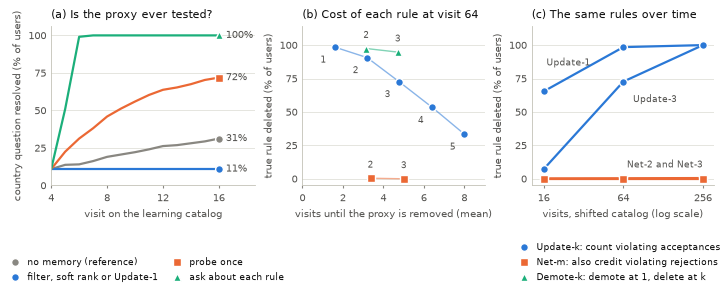

In [21]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"      # validated for colour-vision deficiency on white
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.8,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.6, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-", "axes.axisbelow": True,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "pdf.fonttype": 42, "ps.fonttype": 42, "xtick.major.size": 2.5, "ytick.major.size": 0,
})
FIG_SCOPE, FIG_NOISE = "all", "5%"
RING = dict(markeredgecolor=SURFACE, markeredgewidth=1.0)

fig, axes = plt.subplots(1, 3, figsize=(7.1, 2.75), constrained_layout=True, gridspec_kw={"width_ratios": [1.12, 1, 1]})
MS = {"o": 5.6, "s": 5.2, "^": 6.4}

# (a) entrenchment
ax = axes[0]
src = "naive shared-attribute rule, 4 visits"
xs = np.arange(START, END + 1)
series = [
    ("no memory (reference)", ENTRENCH_CURVES[("memoryless reference", "all users")], MUTED, "o"),
    ("filter, soft rank or Update-1", ENTRENCH_CURVES[(src, "enforce")], BLUE, "o"),
    ("probe once", ENTRENCH_CURVES[(src, "probe")], ORANGE, "s"),
    ("ask about each rule", ENTRENCH_CURVES[(src, "ask")], AQUA, "^"),
]
assert np.allclose(ENTRENCH_CURVES[(src, "enforce")], ENTRENCH_CURVES[(src, "soft")])
assert np.allclose(ENTRENCH_CURVES[(src, "enforce")], ENTRENCH_CURVES[(src, "update1")])
h_a = []
for name, y, col, mk in series:
    ax.plot(xs, 100 * y, color=col, lw=1.6, solid_capstyle="round")
    h_a.append(ax.plot(xs[-1], 100 * y[-1], mk, color=col, ms=MS[mk], **RING, clip_on=False, label=name, linestyle="none")[0])
    ax.annotate(f"{100 * y[-1]:.0f}%", (xs[-1], 100 * y[-1]), xytext=(5, 0), textcoords="offset points",
                va="center", ha="left", color=INK2, fontsize=7)
ax.set_xlim(START, 18.6); ax.set_ylim(0, 106); ax.set_xticks([4, 8, 12, 16]); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("visit on the learning catalog"); ax.set_ylabel("country question resolved (% of users)")
ax.set_title("(a) Is the proxy ever tested?", loc="left", color=INK)

# (b) trade-off at visit 64
ax = axes[1]
fam = {"Update": (BLUE, "o", "Update-k: count violating acceptances"),
       "Net": (ORANGE, "s", "Net-m: also credit violating rejections"),
       "Demote": (AQUA, "^", "Demote-k: demote at 1, delete at k")}
lab_off = {"Update": (-6, -6, "right", "top"), "Net": (0, 6, "center", "bottom"), "Demote": (0, 6, "center", "bottom")}
dL = UPD[(UPD["user type"] == "L") & (UPD["T"] == 64) & (UPD["noise"] == FIG_NOISE) & UPD["change at"].isna()].set_index("rule")
dLC = UPD[(UPD["user type"] == "LC") & (UPD["cells"] == FIG_SCOPE) & (UPD["T"] == 64) & (UPD["noise"] == FIG_NOISE)
          & UPD["change at"].isna()].set_index("rule")
h_b = []
for f, (col, mk, lab) in fam.items():
    rules = [r for r in UPDATE_RULES if r.startswith(f)]
    x = [dL.loc[r, "mean visits to proxy removal (censored)"] for r in rules]
    y = [100 * dLC.loc[r, "false deletion by 64"] for r in rules]
    ax.plot(x, y, color=col, lw=1.0, alpha=0.55, zorder=2)
    h_b.append(ax.plot(x, y, mk, color=col, ms=MS[mk], **RING, zorder=3, label=lab, linestyle="none")[0])
    dx, dy, ha, va = lab_off[f]
    for r, xi, yi in zip(rules, x, y):
        ax.annotate(r.split("-")[1], (xi, yi), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, color=INK2, fontsize=6.8)
ax.set_xlim(0, 9); ax.set_ylim(-5, 114); ax.set_yticks([0, 25, 50, 75, 100]); ax.set_xticks([0, 2, 4, 6, 8])
ax.set_xlabel("visits until the proxy is removed (mean)"); ax.set_ylabel("true rule deleted (% of users)")
ax.set_title("(b) Cost of each rule at visit 64", loc="left", color=INK)

# (c) horizon
ax = axes[2]
d = UPD[(UPD["T"] == 256) & (UPD["user type"] == "LC") & (UPD["cells"] == FIG_SCOPE) & (UPD["noise"] == FIG_NOISE)].set_index("rule")
hz = [16, 64, 256]
for r in ("Update-1", "Update-3", "Net-2", "Net-3"):
    col, mk, _ = fam[r.split("-")[0]]
    y = [100 * d.loc[r, f"false deletion by {h}"] for h in hz]
    ax.plot(hz, y, color=col, lw=1.6, solid_capstyle="round")
    ax.plot(hz, y, mk, color=col, ms=MS[mk], **RING, linestyle="none", clip_on=False)
ax.annotate("Update-1", (16, 100 * d.loc["Update-1", "false deletion by 16"]), xytext=(2, 17), textcoords="offset points",
            ha="left", va="bottom", color=INK2, fontsize=6.8)
ax.annotate("Update-3", (64, 100 * d.loc["Update-3", "false deletion by 64"]), xytext=(7, -9), textcoords="offset points",
            ha="left", va="top", color=INK2, fontsize=6.8)
ax.annotate("Net-2 and Net-3", (256, 100 * d.loc["Net-2", "false deletion by 256"]), xytext=(0, 6), textcoords="offset points",
            ha="right", va="bottom", color=INK2, fontsize=6.8)
ax.set_xscale("log", base=2); ax.set_xticks(hz); ax.set_xticklabels([str(h) for h in hz]); ax.minorticks_off()
ax.set_xlim(13, 310); ax.set_ylim(-5, 114); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xlabel("visits, shifted catalog (log scale)"); ax.set_ylabel("true rule deleted (% of users)")
ax.set_title("(c) The same rules over time", loc="left", color=INK)

fig.legend(handles=h_a, loc="outside lower left", ncol=2, frameon=False, handletextpad=0.3, columnspacing=1.0, borderaxespad=0.2)
fig.legend(handles=h_b, loc="outside lower right", ncol=1, frameon=False, handletextpad=0.3, borderaxespad=0.2)
fig.savefig(FIGS / "interface_audit.pdf"); fig.savefig(FIGS / "interface_audit.png", dpi=220)
plt.show()

In [22]:
# Headline numbers, collected in one place and written to results/summary.json.
def cell(utype, rule, noise, scope="feasible", T=64, change=None):
    d = UPD[(UPD["user type"] == utype) & (UPD["rule"] == rule) & (UPD["noise"] == noise) & (UPD["cells"] == scope) & (UPD["T"] == T)
            & (UPD["change at"].isna() if change is None else UPD["change at"] == change)]
    return d.iloc[0]

two = SOURCES["two rules, hand-set"]
hard = serve_many(two, POL["enforce"], "L", 1, USERS); soft = serve_many(two, POL["soft"], "L", 1, USERS)
src = "naive shared-attribute rule, 4 visits"
SUMMARY = {
    "setup": {"seed": CFG["seed"], "catalog_sha256": CATALOG_SHA256, "pairs": CFG["pairs"],
              "feasible_cells": {f"{W.lang}/{W.country}": len(W.cells) for W in WORLDS},
              "writing_users": len(WRITE_USERS), "serving_users": len(USERS),
              "update_users_per_cell": CFG["n_update_users"] * len(WORLDS)},
    "ambiguity_writing_users": {k: sum(not has_counterexample(W, prefix(HIST[(W.pidx, u, "L")], k), W.C) for W, u in WRITE_USERS)
                                for k in CFG["prefixes"]},
    "logical_reference_8_visits": {
        "language_established": sum(ref_version_space(W, prefix(HIST[(W.pidx, u, "L")], K)).get(W.L) == "established" for W, u in WRITE_USERS),
        "country_established": sum(ref_version_space(W, prefix(HIST[(W.pidx, u, "L")], K)).get(W.C) == "established" for W, u in WRITE_USERS)},
    "model_arms_complete": [f"{m}/{a}" for (m, a), ok in READY.items() if ok],
    "serving_two_rule_memory_shifted_catalog": {
        "hard_filter_success_pct": round(100 * ratio_ci(hard, "sB", "feas")[0], 1),
        "soft_rank_success_pct": round(100 * ratio_ci(soft, "sB", "feas")[0], 1),
        "soft_rank_first_accept_pct": round(100 * ratio_ci(soft, "s1", "feas")[0], 1)},
    "utility_on_learning_catalog_points": {"no_memory_level": round(100 * float(s_none.mean()), 1),
                                           "country_alone": round(100 * float((s_C - s_none).mean()), 1),
                                           "language_alone": round(100 * float((s_L - s_none).mean()), 1),
                                           "country_given_language": round(100 * float((s_LC - s_L).mean()), 1)},
    "entrenchment_resolved_at_visit_16_pct": {
        "memoryless": round(100 * float(ENTRENCH_CURVES[("memoryless reference", "all users")][-1]), 1),
        "filter_or_soft_rank": round(100 * float(ENTRENCH_CURVES[(src, "enforce")][-1]), 1),
        "probe_once": round(100 * float(ENTRENCH_CURVES[(src, "probe")][-1]), 1),
        "ask": round(100 * float(ENTRENCH_CURVES[(src, "ask")][-1]), 1)},
    "update_false_deletion_pct": {
        f"{scope} cells, {noise}, by visit {h}": {r: round(100 * float(cell("LC", r, noise, scope)[f"false deletion by {h}"]), 2)
                                                 for r in ("Update-1", "Update-3", "Net-2", "Net-3")}
        for scope in ("feasible", "all") for noise in ("5%", "10%") for h in (16, 64)},
    "update_mean_visits_to_proxy_removal_5pct": {r: round(float(cell("L", r, "5%")["mean visits to proxy removal (censored)"]), 2)
                                                for r in UPDATE_RULES},
    "preference_change_visits_to_deletion_0pct": {r: round(float(cell("LC", r, "0%", "all", change=9)["visits from change to deletion (censored)"]), 1)
                                                 for r in UPDATE_RULES},
}
(RESULTS / "summary.json").write_text(json.dumps(SUMMARY, indent=1, ensure_ascii=False))
print(json.dumps(SUMMARY, indent=1, ensure_ascii=False))

{
 "setup": {
  "seed": 20261115,
  "catalog_sha256": "19e9fa3a4db03de8f8bb8cdd8f7b231346a44f21cefca18947b7b10485d7093f",
  "pairs": [
   [
    "Spanish",
    "Spain",
    90
   ],
   [
    "French",
    "France",
    80
   ],
   [
    "Russian",
    "Russia",
    50
   ],
   [
    "German",
    "Germany",
    40
   ]
  ],
  "feasible_cells": {
   "Spanish/Spain": 22,
   "French/France": 23,
   "Russian/Russia": 8,
   "German/Germany": 17
  },
  "writing_users": 80,
  "serving_users": 320,
  "update_users_per_cell": 2000
 },
 "ambiguity_writing_users": {
  "4": 67,
  "8": 62,
  "16": 52
 },
 "logical_reference_8_visits": {
  "language_established": 29,
  "country_established": 0
 },
 "model_arms_complete": [],
 "serving_two_rule_memory_shifted_catalog": {
  "hard_filter_success_pct": 34.7,
  "soft_rank_success_pct": 100.0,
  "soft_rank_first_accept_pct": 95.9
 },
 "utility_on_learning_catalog_points": {
  "no_memory_level": 48.7,
  "country_alone": 51.3,
  "language_alone": 51.3,
  "co